In [ ]:
!nvidia-smi


Sun Oct 18 12:07:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os, sys, json, subprocess
from importlib.metadata import version, PackageNotFoundError
from datetime import datetime, timezone
import torch

def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return None

torch.cuda.init()
temporary = torch.empty(1, device="cuda:0")
torch.cuda.synchronize()
del temporary
torch.cuda.empty_cache()
torch.cuda.synchronize()
free_bytes, total_bytes = torch.cuda.mem_get_info(0)

snapshot = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "torch": torch.__version__,
    "torch_cuda_runtime": torch.version.cuda,
    "transformers": package_version("transformers"),
    "gpu_name": torch.cuda.get_device_name(0),
    "gpu_identity_csv": subprocess.check_output(
        ["nvidia-smi", "--query-gpu=uuid,name,driver_version",
         "--format=csv,noheader"], text=True
    ).strip(),
    "cuda_free_bytes": free_bytes,
    "cuda_total_bytes": total_bytes,
    "allocated_bytes": torch.cuda.memory_allocated(0),
    "reserved_bytes": torch.cuda.memory_reserved(0),
    "allocator_env": {
        key: os.environ.get(key)
        for key in ("PYTORCH_CUDA_ALLOC_CONF", "PYTORCH_ALLOC_CONF")
    },
    "current_pid": os.getpid(),
    "gpu_processes": subprocess.check_output(
        ["nvidia-smi", "--query-compute-apps=pid,process_name,used_gpu_memory",
         "--format=csv,noheader"], text=True
    ).strip(),
}
print(json.dumps(snapshot, indent=2))

{
  "timestamp_utc": "2026-10-18T12:14:03.473613+00:00",
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "torch": "2.11.0+cu130",
  "torch_cuda_runtime": "13.0",
  "transformers": "5.18.0",
  "gpu_name": "Tesla T4",
  "gpu_identity_csv": "GPU-68cbea81-a683-22be-800d-74ff2d51155e, Tesla T4, 580.82.07",
  "cuda_free_bytes": 15527116800,
  "cuda_total_bytes": 15637086208,
  "allocated_bytes": 0,
  "reserved_bytes": 0,
  "allocator_env": {
    "PYTORCH_CUDA_ALLOC_CONF": null,
    "PYTORCH_ALLOC_CONF": null
  },
  "current_pid": 2797,
  "gpu_processes": "2797, /usr/bin/python3, 102 MiB"
}


# Person 1 - Phase 1 auditable preparation

The two earlier inventory cells and outputs are preserved above. The Python session was restarted before this section to release the notebook-owned CUDA context.

Every preparation command below is visible and recorded. Source code is pinned to cf50e692ac52cbdc85824fe39252507f0f0e73c5. No model load, forward pass, attention benchmark or OOM attempt is authorized in this section. Runtime reconciliation and independent review remain required before formal preregistration.

Save this executed notebook together with the exported evidence ZIP.

In [ ]:
# Step 1: command journal and isolated run directory
import os, sys, json, hashlib, subprocess, uuid, shutil
from datetime import datetime, timezone
from pathlib import Path

# Keep the notebook itself CPU-only. A previous GPU-owning cell requires restart.
existing_torch = sys.modules.get("torch")
if existing_torch is not None and existing_torch.cuda.is_initialized():
    raise RuntimeError("Restart the runtime first: the notebook must not own a CUDA context.")

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:8]
RUN_ROOT = Path(os.environ.get("KVCACHE_NOTEBOOK_RUNS_ROOT", "/content/kvcache-evidence"))
RUN_DIR = RUN_ROOT / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
JOURNAL = RUN_DIR / "commands.jsonl"

def audit_event(event):
    with JOURNAL.open("a", encoding="utf-8") as handle:
        handle.write(json.dumps(event, allow_nan=False) + "\n")
        handle.flush()
        os.fsync(handle.fileno())

def audit_run(label, command, *, cwd=None, env=None, timeout=300):
    if not label or any(c not in "abcdefghijklmnopqrstuvwxyz0123456789-" for c in label):
        raise ValueError("Use a simple unique command label")
    out_path = RUN_DIR / (label + ".stdout.txt")
    err_path = RUN_DIR / (label + ".stderr.txt")
    if out_path.exists() or err_path.exists():
        raise FileExistsError("Use a new label or a new run; prior outputs are preserved")
    audit_event({"event":"command_started", "label":label, "argv":command,
                 "cwd":str(cwd) if cwd else None,
                 "timestamp_utc":datetime.now(timezone.utc).isoformat(),
                 "allocator_env":{key:(env or os.environ).get(key) for key in
                     ("PYTORCH_CUDA_ALLOC_CONF", "PYTORCH_ALLOC_CONF")}})
    try:
        completed = subprocess.run(command, cwd=cwd, env=env, timeout=timeout,
                                   text=True, encoding="utf-8", errors="replace",
                                   capture_output=True, check=False)
    except Exception as error:
        err_path.write_text(repr(error) + "\n", encoding="utf-8")
        audit_event({"event":"command_failed_to_complete", "label":label,
                     "error":repr(error), "timestamp_utc":datetime.now(timezone.utc).isoformat()})
        raise
    out_path.write_text(completed.stdout, encoding="utf-8")
    err_path.write_text(completed.stderr, encoding="utf-8")
    audit_event({"event":"command_finished", "label":label, "returncode":completed.returncode,
                 "timestamp_utc":datetime.now(timezone.utc).isoformat(),
                 "stdout_sha256":hashlib.sha256(out_path.read_bytes()).hexdigest(),
                 "stderr_sha256":hashlib.sha256(err_path.read_bytes()).hexdigest()})
    print("COMMAND:", command)
    print("RETURN CODE:", completed.returncode)
    print(completed.stdout[:5000])
    if completed.stderr:
        print(completed.stderr[:5000])
    if completed.returncode:
        raise RuntimeError(f"{label} failed; full output is preserved in {RUN_DIR}")
    return completed

print("Evidence directory:", RUN_DIR)
print("Local /content storage is ephemeral. Export the evidence ZIP before disconnecting.")


Evidence directory: /content/kvcache-evidence/20261018T123226Z-ad6f415d
Local /content storage is ephemeral. Export the evidence ZIP before disconnecting.


In [ ]:
# Step 2a: preserve checkout failure details as plain text
import sys
print("Last exception:", repr(getattr(sys, "last_value", None)))
print("Run directory:", RUN_DIR)
print("Command journal:\n", JOURNAL.read_text() if JOURNAL.exists() else "not created")
for name in ("git-clone.stdout.txt", "git-clone.stderr.txt"):
    path = RUN_DIR / name
    print(name, path.read_text() if path.exists() else "not created")

Last exception: RuntimeError('git-clone failed; full output is preserved in /content/kvcache-evidence/20261018T123226Z-ad6f415d')
Run directory: /content/kvcache-evidence/20261018T123226Z-ad6f415d
Command journal:
 {"event": "command_started", "label": "git-clone", "argv": ["git", "clone", "--no-checkout", "https://github.com/DevanshSharma351/KV-Cache-Scaling.git", "/content/kvcache-evidence/20261018T123226Z-ad6f415d/source"], "cwd": null, "timestamp_utc": "2026-10-18T12:33:02.600702+00:00", "allocator_env": {"PYTORCH_CUDA_ALLOC_CONF": null, "PYTORCH_ALLOC_CONF": null}}
{"event": "command_finished", "label": "git-clone", "returncode": 128, "timestamp_utc": "2026-10-18T12:33:03.069332+00:00", "stdout_sha256": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855", "stderr_sha256": "4b1439d67f6725482eab782f65235874aeedc6f311601b65102436215e378136"}

git-clone.stdout.txt 
git-clone.stderr.txt Cloning into '/content/kvcache-evidence/20261018T123226Z-ad6f415d/source'...
fatal: c

In [ ]:
# Step 2: clone and resolve the exact reviewed source commit
REPO_URL = "https://github.com/DevanshSharma351/KV-Cache-Scaling.git"
SOURCE_REF = "cf50e692ac52cbdc85824fe39252507f0f0e73c5"  # Replace with the recorded SHA for an exact replay.
REPO = RUN_DIR / "source"
audit_run("git-clone", ["git", "clone", "--no-checkout", REPO_URL, str(REPO)])
resolved = audit_run("git-resolve", ["git", "rev-parse", SOURCE_REF], cwd=REPO).stdout.strip()
audit_run("git-checkout", ["git", "checkout", "--detach", resolved], cwd=REPO)
source_record = {"repository":REPO_URL, "requested_ref":SOURCE_REF, "resolved_commit":resolved}
(RUN_DIR / "source.json").write_text(json.dumps(source_record, indent=2) + "\n")
CPU_ENV = dict(os.environ, PYTHONPATH=str(REPO / "src"))
print(json.dumps(source_record, indent=2))


COMMAND: ['git', 'clone', '--no-checkout', 'https://github.com/DevanshSharma351/KV-Cache-Scaling.git', '/content/kvcache-evidence/20261018T123226Z-ad6f415d/source']
RETURN CODE: 128

Cloning into '/content/kvcache-evidence/20261018T123226Z-ad6f415d/source'...
fatal: could not read Username for 'https://github.com': No such device or address



RuntimeError: git-clone failed; full output is preserved in /content/kvcache-evidence/20261018T123226Z-ad6f415d

In [ ]:
# Step 2b: retry after repository was made public; preserve the failed attempt above
REPO_URL = "https://github.com/DevanshSharma351/KV-Cache-Scaling.git"
SOURCE_REF = "cf50e692ac52cbdc85824fe39252507f0f0e73c5"  # Replace with the recorded SHA for an exact replay.
REPO = RUN_DIR / "source"
audit_run("git-clone-public-retry", ["git", "clone", "--no-checkout", REPO_URL, str(REPO)])
resolved = audit_run("git-resolve", ["git", "rev-parse", SOURCE_REF], cwd=REPO).stdout.strip()
audit_run("git-checkout", ["git", "checkout", "--detach", resolved], cwd=REPO)
source_record = {"repository":REPO_URL, "requested_ref":SOURCE_REF, "resolved_commit":resolved}
(RUN_DIR / "source.json").write_text(json.dumps(source_record, indent=2) + "\n")
CPU_ENV = dict(os.environ, PYTHONPATH=str(REPO / "src"))
print(json.dumps(source_record, indent=2))


COMMAND: ['git', 'clone', '--no-checkout', 'https://github.com/DevanshSharma351/KV-Cache-Scaling.git', '/content/kvcache-evidence/20261018T123226Z-ad6f415d/source']
RETURN CODE: 0

Cloning into '/content/kvcache-evidence/20261018T123226Z-ad6f415d/source'...

COMMAND: ['git', 'rev-parse', 'cf50e692ac52cbdc85824fe39252507f0f0e73c5']
RETURN CODE: 0
cf50e692ac52cbdc85824fe39252507f0f0e73c5

COMMAND: ['git', 'checkout', '--detach', 'cf50e692ac52cbdc85824fe39252507f0f0e73c5']
RETURN CODE: 0

HEAD is now at cf50e69 feat(p1): add auditable Colab preparation and runtime reconciliation

{
  "repository": "https://github.com/DevanshSharma351/KV-Cache-Scaling.git",
  "requested_ref": "cf50e692ac52cbdc85824fe39252507f0f0e73c5",
  "resolved_commit": "cf50e692ac52cbdc85824fe39252507f0f0e73c5"
}


In [ ]:
# Step 3: CPU tests and environment inventory
audit_run("cpu-tests", [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
          cwd=REPO, env=CPU_ENV)
audit_run("package-freeze", [sys.executable, "-m", "pip", "freeze", "--all"])
audit_run("driver-before-context", ["nvidia-smi"])


COMMAND: ['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'tests', '-v']
RETURN CODE: 0

test_exact_free_budget_is_not_reduced_twice (test_environment.EnvironmentTests.test_exact_free_budget_is_not_reduced_twice) ... ok
test_invalid_or_non_context_inventory_is_rejected (test_environment.EnvironmentTests.test_invalid_or_non_context_inventory_is_rejected) ... ok
test_other_users_are_reported_instead_of_hidden (test_environment.EnvironmentTests.test_other_users_are_reported_instead_of_hidden) ... ok
test_runtime_mismatch_is_visible_and_never_authorizes_probes (test_environment.EnvironmentTests.test_runtime_mismatch_is_visible_and_never_authorizes_probes) ... ok
test_same_stack_still_requires_review_and_receipt (test_environment.EnvironmentTests.test_same_stack_still_requires_review_and_receipt) ... ok
test_bad_config_shapes_and_unsupported_execution_rejected (test_model_math.ModelMathTests.test_bad_config_shapes_and_unsupported_execution_rejected) ... ok
test_batch_scales_variable

CompletedProcess(args=['nvidia-smi'], returncode=0, stdout='Sun Oct 18 12:42:37 2026       \n+-----------------------------------------------------------------------------------------+\n| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |\n+-----------------------------------------+------------------------+----------------------+\n| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |\n| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |\n|                                         |                        |               MIG M. |\n|=========================================+========================+======================|\n|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |\n| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |\n|                                         |                        |  

In [ ]:
# Step 4: isolated context-only inventory
context_script = r"""
import json, os, sys, subprocess
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import torch

def installed(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return None

if torch.cuda.is_initialized():
    raise RuntimeError("Expected a new interpreter without an initialized CUDA context")
torch.cuda.init()
temporary = torch.empty(1, device="cuda:0")
torch.cuda.synchronize()
del temporary
torch.cuda.empty_cache()
torch.cuda.synchronize()
free_bytes, total_bytes = torch.cuda.mem_get_info(0)
snapshot = {
    "timestamp_utc":datetime.now(timezone.utc).isoformat(),
    "python":sys.version, "torch":torch.__version__,
    "torch_cuda_runtime":torch.version.cuda,
    "transformers":installed("transformers"),
    "gpu_name":torch.cuda.get_device_name(0),
    "gpu_identity_csv":subprocess.check_output(
        ["nvidia-smi", "--query-gpu=uuid,name,driver_version", "--format=csv,noheader"], text=True).strip(),
    "cuda_free_bytes":free_bytes, "cuda_total_bytes":total_bytes,
    "allocated_bytes":torch.cuda.memory_allocated(0),
    "reserved_bytes":torch.cuda.memory_reserved(0),
    "allocator_env":{key:os.environ.get(key) for key in
                     ("PYTORCH_CUDA_ALLOC_CONF", "PYTORCH_ALLOC_CONF")},
    "current_pid":os.getpid(),
    "gpu_processes":subprocess.check_output(
        ["nvidia-smi", "--query-compute-apps=pid,process_name,used_gpu_memory", "--format=csv,noheader"], text=True).strip(),
    "compiled_cuda_architectures":torch.cuda.get_arch_list(),
    "cuda_visible_devices":os.environ.get("CUDA_VISIBLE_DEVICES"),
    "collection_kind":"isolated context-only worker; no model APIs invoked"
}
print(json.dumps(snapshot, indent=2))
"""
collected = audit_run("context-inventory", [sys.executable, "-c", context_script], timeout=180)
INVENTORY_PATH = RUN_DIR / "context-inventory.json"
INVENTORY_PATH.write_text(json.dumps(json.loads(collected.stdout), indent=2) + "\n")
audit_run("driver-after-worker-exit", ["nvidia-smi"])


COMMAND: ['/usr/bin/python3', '-c', '\nimport json, os, sys, subprocess\nfrom datetime import datetime, timezone\nfrom importlib.metadata import version, PackageNotFoundError\nimport torch\n\ndef installed(name):\n    try:\n        return version(name)\n    except PackageNotFoundError:\n        return None\n\nif torch.cuda.is_initialized():\n    raise RuntimeError("Expected a new interpreter without an initialized CUDA context")\ntorch.cuda.init()\ntemporary = torch.empty(1, device="cuda:0")\ntorch.cuda.synchronize()\ndel temporary\ntorch.cuda.empty_cache()\ntorch.cuda.synchronize()\nfree_bytes, total_bytes = torch.cuda.mem_get_info(0)\nsnapshot = {\n    "timestamp_utc":datetime.now(timezone.utc).isoformat(),\n    "python":sys.version, "torch":torch.__version__,\n    "torch_cuda_runtime":torch.version.cuda,\n    "transformers":installed("transformers"),\n    "gpu_name":torch.cuda.get_device_name(0),\n    "gpu_identity_csv":subprocess.check_output(\n        ["nvidia-smi", "--query-gpu=u

CompletedProcess(args=['nvidia-smi'], returncode=0, stdout='Sun Oct 18 12:42:52 2026       \n+-----------------------------------------------------------------------------------------+\n| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |\n+-----------------------------------------+------------------------+----------------------+\n| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |\n| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |\n|                                         |                        |               MIG M. |\n|=========================================+========================+======================|\n|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |\n| N/A   41C    P0             27W /   70W |       0MiB /  15360MiB |      2%      Default |\n|                                         |                        |  

In [ ]:
# Step 5: installed API inspection; no model instantiated
inspection_script = r"""
import hashlib, inspect, json
from pathlib import Path
report = {"inspection_only":True, "model_instantiated":False}
try:
    import torch
    import transformers
    from transformers.models.qwen2.modeling_qwen2 import Qwen2ForCausalLM
    from transformers.cache_utils import DynamicCache, StaticCache
    import transformers.integrations.sdpa_attention as sdpa
    objects = {"Qwen2ForCausalLM.forward":Qwen2ForCausalLM.forward,
               "DynamicCache":DynamicCache, "StaticCache":StaticCache,
               "sdpa_attention_forward":sdpa.sdpa_attention_forward}
    report["torch"] = torch.__version__
    report["transformers"] = transformers.__version__
    report["signatures"] = {name:str(inspect.signature(obj)) for name,obj in objects.items()}
    report["source_files"] = {}
    for obj in objects.values():
        filename = inspect.getsourcefile(obj)
        if filename:
            path = Path(filename)
            report["source_files"][path.name] = hashlib.sha256(path.read_bytes()).hexdigest()
    adapter_source = inspect.getsource(sdpa.sdpa_attention_forward)
    report["adapter_contains_enable_gqa"] = "enable_gqa" in adapter_source
    report["kernel_execution_tested"] = False
except Exception as error:
    report["inspection_error"] = repr(error)
print(json.dumps(report, indent=2))
"""
audit_run("installed-api-inspection", [sys.executable, "-c", inspection_script], timeout=180)


COMMAND: ['/usr/bin/python3', '-c', '\nimport hashlib, inspect, json\nfrom pathlib import Path\nreport = {"inspection_only":True, "model_instantiated":False}\ntry:\n    import torch\n    import transformers\n    from transformers.models.qwen2.modeling_qwen2 import Qwen2ForCausalLM\n    from transformers.cache_utils import DynamicCache, StaticCache\n    import transformers.integrations.sdpa_attention as sdpa\n    objects = {"Qwen2ForCausalLM.forward":Qwen2ForCausalLM.forward,\n               "DynamicCache":DynamicCache, "StaticCache":StaticCache,\n               "sdpa_attention_forward":sdpa.sdpa_attention_forward}\n    report["torch"] = torch.__version__\n    report["transformers"] = transformers.__version__\n    report["signatures"] = {name:str(inspect.signature(obj)) for name,obj in objects.items()}\n    report["source_files"] = {}\n    for obj in objects.values():\n        filename = inspect.getsourcefile(obj)\n        if filename:\n            path = Path(filename)\n            rep

CompletedProcess(args=['/usr/bin/python3', '-c', '\nimport hashlib, inspect, json\nfrom pathlib import Path\nreport = {"inspection_only":True, "model_instantiated":False}\ntry:\n    import torch\n    import transformers\n    from transformers.models.qwen2.modeling_qwen2 import Qwen2ForCausalLM\n    from transformers.cache_utils import DynamicCache, StaticCache\n    import transformers.integrations.sdpa_attention as sdpa\n    objects = {"Qwen2ForCausalLM.forward":Qwen2ForCausalLM.forward,\n               "DynamicCache":DynamicCache, "StaticCache":StaticCache,\n               "sdpa_attention_forward":sdpa.sdpa_attention_forward}\n    report["torch"] = torch.__version__\n    report["transformers"] = transformers.__version__\n    report["signatures"] = {name:str(inspect.signature(obj)) for name,obj in objects.items()}\n    report["source_files"] = {}\n    for obj in objects.values():\n        filename = inspect.getsourcefile(obj)\n        if filename:\n            path = Path(filename)\n  

In [ ]:
# Step 6: conditional theory using the new exact-byte inventory
prediction_script = r"""
import hashlib, json, sys
from pathlib import Path
from kv_cache_scaling.environment import context_prediction
from kv_cache_scaling.model_math import Architecture
source = Path(sys.argv[1])
config = Path("configs/models/qwen2.5-1.5b.json")
arch = Architecture.from_config(json.loads(config.read_text()))
report = context_prediction(json.loads(source.read_text()), arch)
report["snapshot_sha256"] = hashlib.sha256(source.read_bytes()).hexdigest()
report["config_sha256"] = hashlib.sha256(config.read_bytes()).hexdigest()
Path(sys.argv[2]).write_text(json.dumps(report, indent=2) + "\n")
print(json.dumps(report, indent=2))
"""
REPORT_PATH = RUN_DIR / "conditional-prediction.json"
audit_run("conditional-prediction", [sys.executable, "-c", prediction_script,
          str(INVENTORY_PATH), str(REPORT_PATH)], cwd=REPO, env=CPU_ENV)
report = json.loads(REPORT_PATH.read_text())
assert report["gpu_measurements_authorized"] is False
print("MODEL MEASUREMENT GATE: CLOSED — reconcile runtime and obtain review/receipt first.")


COMMAND: ['/usr/bin/python3', '-c', '\nimport hashlib, json, sys\nfrom pathlib import Path\nfrom kv_cache_scaling.environment import context_prediction\nfrom kv_cache_scaling.model_math import Architecture\nsource = Path(sys.argv[1])\nconfig = Path("configs/models/qwen2.5-1.5b.json")\narch = Architecture.from_config(json.loads(config.read_text()))\nreport = context_prediction(json.loads(source.read_text()), arch)\nreport["snapshot_sha256"] = hashlib.sha256(source.read_bytes()).hexdigest()\nreport["config_sha256"] = hashlib.sha256(config.read_bytes()).hexdigest()\nPath(sys.argv[2]).write_text(json.dumps(report, indent=2) + "\\n")\nprint(json.dumps(report, indent=2))\n', '/content/kvcache-evidence/20261018T123226Z-ad6f415d/context-inventory.json', '/content/kvcache-evidence/20261018T123226Z-ad6f415d/conditional-prediction.json']
RETURN CODE: 0
{
  "status": "CONDITIONAL_THEORY_NOT_PREREGISTERED",
  "gpu_measurements_authorized": false,
  "evidence_origin": "caller-supplied context invent

In [ ]:
# Step 7: regenerate generic theory into a new directory
audit_run("generic-prediction-draft", [sys.executable, "-m", "kv_cache_scaling",
          "prepare-prereg", "--output", str(RUN_DIR / "generic-theory-draft")], cwd=REPO, env=CPU_ENV)


COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'prepare-prereg', '--output', '/content/kvcache-evidence/20261018T123226Z-ad6f415d/generic-theory-draft']
RETURN CODE: 0
{
  "status": "DRAFT_THEORY_ONLY_NOT_PREREGISTERED",
  "output_directory": "/content/kvcache-evidence/20261018T123226Z-ad6f415d/generic-theory-draft",
  "gpu_measurements_authorized": false
}



CompletedProcess(args=['/usr/bin/python3', '-m', 'kv_cache_scaling', 'prepare-prereg', '--output', '/content/kvcache-evidence/20261018T123226Z-ad6f415d/generic-theory-draft'], returncode=0, stdout='{\n  "status": "DRAFT_THEORY_ONLY_NOT_PREREGISTERED",\n  "output_directory": "/content/kvcache-evidence/20261018T123226Z-ad6f415d/generic-theory-draft",\n  "gpu_measurements_authorized": false\n}\n', stderr='')

In [ ]:
# Step 8: verify saved artifacts and summarize the actual run
checks = {"source_commit": resolved, "tests_passed": "Ran 36 tests" in (RUN_DIR / "cpu-tests.stderr.txt").read_text(), "test_suite_ok": "\nOK\n" in (RUN_DIR / "cpu-tests.stderr.txt").read_text(), "context_snapshot": json.loads(INVENTORY_PATH.read_text()), "installed_api": json.loads((RUN_DIR / "installed-api-inspection.stdout.txt").read_text()), "gpu_measurements_authorized": False}
assert checks["tests_passed"] and checks["test_suite_ok"]
assert checks["installed_api"].get("inspection_error") is None
assert checks["context_snapshot"]["allocated_bytes"] == 0
assert checks["context_snapshot"]["reserved_bytes"] == 0
assert json.loads(REPORT_PATH.read_text())["gpu_measurements_authorized"] is False
(RUN_DIR / "execution-summary.json").write_text(json.dumps(checks, indent=2) + "\n")
print(json.dumps(checks, indent=2))
print("Preparation complete; model loads, forwards, attention kernels and OOM probes were not run.")

{
  "source_commit": "cf50e692ac52cbdc85824fe39252507f0f0e73c5",
  "tests_passed": true,
  "test_suite_ok": true,
  "context_snapshot": {
    "timestamp_utc": "2026-10-18T12:42:51.766411+00:00",
    "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
    "torch": "2.11.0+cu130",
    "torch_cuda_runtime": "13.0",
    "transformers": "5.18.0",
    "gpu_name": "Tesla T4",
    "gpu_identity_csv": "GPU-68cbea81-a683-22be-800d-74ff2d51155e, Tesla T4, 580.82.07",
    "cuda_free_bytes": 15527116800,
    "cuda_total_bytes": 15637086208,
    "allocated_bytes": 0,
    "reserved_bytes": 0,
    "allocator_env": {
      "PYTORCH_CUDA_ALLOC_CONF": null,
      "PYTORCH_ALLOC_CONF": null
    },
    "current_pid": 11894,
    "gpu_processes": "11894, /usr/bin/python3, 102 MiB",
    "compiled_cuda_architectures": [
      "sm_75",
      "sm_80",
      "sm_86",
      "sm_90",
      "sm_100",
      "sm_120"
    ],
    "cuda_visible_devices": null,
    "collection_kind": "isolated context-only wor

In [ ]:
# Step 9: export command logs and verified evidence
import zipfile
files = [path for path in RUN_DIR.rglob("*")
         if path.is_file() and REPO not in path.parents and path.name != "evidence-manifest.json"]
manifest = {"resolved_source_commit":resolved, "files_sha256":{
    str(path.relative_to(RUN_DIR)):hashlib.sha256(path.read_bytes()).hexdigest()
    for path in sorted(files)}}
manifest_path = RUN_DIR / "evidence-manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
archive = RUN_DIR.parent / (RUN_DIR.name + ".zip")
with zipfile.ZipFile(archive, "x", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(files + [manifest_path]):
        bundle.write(path, arcname=str(path.relative_to(RUN_DIR)))
print("Evidence ZIP:", archive)
print("Archive SHA-256:", hashlib.sha256(archive.read_bytes()).hexdigest())
print("Export the executed .ipynb as well; keep both until reviewed results are committed.")


Evidence ZIP: /content/kvcache-evidence/20261018T123226Z-ad6f415d.zip
Archive SHA-256: 9c96fd1de0f4b51df2309589da1f2a681150094f1549d29cf9e3add86fd6939c
Export the executed .ipynb as well; keep both until reviewed results are committed.


In [ ]:
# Step 10: download the existing checksummed evidence archive
from google.colab import files as colab_files
print("Downloading existing archive:", archive)
print("SHA-256:", hashlib.sha256(archive.read_bytes()).hexdigest())
colab_files.download(str(archive))

SHA-256: 9c96fd1de0f4b51df2309589da1f2a681150094f1549d29cf9e3add86fd6939c


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Step 11: text transfer fallback for the existing archive; preserve the download attempt
import base64
print("EVIDENCE_ARCHIVE_BASE64_BEGIN")
print(base64.b64encode(archive.read_bytes()).decode("ascii"))
print("EVIDENCE_ARCHIVE_BASE64_END")

EVIDENCE_ARCHIVE_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
EVIDENCE_ARCHIVE_BASE64_END


## Phase 1 preparation: execution summary

**36 CPU tests passed in Colab.** Source: `cf50e692ac52cbdc85824fe39252507f0f0e73c5`.

Tesla T4 usable budget: **15,527,116,800 bytes (14.46075 GiB)**. The isolated context worker had zero live allocated/reserved tensors; no GPU processes remained after it exited.

Installed API inspection, conditional predictions and a separate generic theory draft completed. The original private-clone failure and successful public retry are preserved above.

The evidence ZIP was recovered through the visible text-transfer cell because browser downloads failed. Its SHA-256 matched `9c96fd1de0f4b51df2309589da1f2a681150094f1549d29cf9e3add86fd6939c`; all 32 manifest entries were verified locally.

**Formal preregistration remains pending:** reconcile the installed runtime, obtain independent review, push the formal prediction and record its receipt. No model load, forward, attention kernel, allocator intervention or OOM attempt was run.

This notebook is the executed audit trail. The ZIP contains the command logs and reports up to archive creation, before the export-attempt/text-transfer cells.

In [ ]:
# Phases 1–3 completion audit: runtime 2025.07, T4; no model measurement
import os, sys, json, hashlib, subprocess, uuid, shutil
from datetime import datetime, timezone
from pathlib import Path

# Keep the notebook itself CPU-only. A previous GPU-owning cell requires restart.
existing_torch = sys.modules.get("torch")
if existing_torch is not None and existing_torch.cuda.is_initialized():
    raise RuntimeError("Restart the runtime first: the notebook must not own a CUDA context.")

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:8]
RUN_ROOT = Path(os.environ.get("KVCACHE_NOTEBOOK_RUNS_ROOT", "/content/kvcache-evidence"))
RUN_DIR = RUN_ROOT / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
JOURNAL = RUN_DIR / "commands.jsonl"

def audit_event(event):
    with JOURNAL.open("a", encoding="utf-8") as handle:
        handle.write(json.dumps(event, allow_nan=False) + "\n")
        handle.flush()
        os.fsync(handle.fileno())

def audit_run(label, command, *, cwd=None, env=None, timeout=300):
    if not label or any(c not in "abcdefghijklmnopqrstuvwxyz0123456789-" for c in label):
        raise ValueError("Use a simple unique command label")
    out_path = RUN_DIR / (label + ".stdout.txt")
    err_path = RUN_DIR / (label + ".stderr.txt")
    if out_path.exists() or err_path.exists():
        raise FileExistsError("Use a new label or a new run; prior outputs are preserved")
    audit_event({"event":"command_started", "label":label, "argv":command,
                 "cwd":str(cwd) if cwd else None,
                 "timestamp_utc":datetime.now(timezone.utc).isoformat(),
                 "allocator_env":{key:(env or os.environ).get(key) for key in
                     ("PYTORCH_CUDA_ALLOC_CONF", "PYTORCH_ALLOC_CONF")}})
    try:
        completed = subprocess.run(command, cwd=cwd, env=env, timeout=timeout,
                                   text=True, encoding="utf-8", errors="replace",
                                   capture_output=True, check=False)
    except Exception as error:
        err_path.write_text(repr(error) + "\n", encoding="utf-8")
        audit_event({"event":"command_failed_to_complete", "label":label,
                     "error":repr(error), "timestamp_utc":datetime.now(timezone.utc).isoformat()})
        raise
    out_path.write_text(completed.stdout, encoding="utf-8")
    err_path.write_text(completed.stderr, encoding="utf-8")
    audit_event({"event":"command_finished", "label":label, "returncode":completed.returncode,
                 "timestamp_utc":datetime.now(timezone.utc).isoformat(),
                 "stdout_sha256":hashlib.sha256(out_path.read_bytes()).hexdigest(),
                 "stderr_sha256":hashlib.sha256(err_path.read_bytes()).hexdigest()})
    print("COMMAND:", command)
    print("RETURN CODE:", completed.returncode)
    print(completed.stdout[:5000])
    if completed.stderr:
        print(completed.stderr[:5000])
    if completed.returncode:
        raise RuntimeError(f"{label} failed; full output is preserved in {RUN_DIR}")
    return completed

print("Evidence directory:", RUN_DIR)
print("Local /content storage is ephemeral. Export the evidence ZIP before disconnecting.")


Evidence directory: /content/kvcache-evidence/20261018T141242Z-a337a6c3
Local /content storage is ephemeral. Export the evidence ZIP before disconnecting.


In [ ]:
# Exact source checkout and metadata only: no model import or forward
REPO_URL = "https://github.com/DevanshSharma351/KV-Cache-Scaling.git"
SOURCE_REF = "072293c3150f3479e853ebfdd874fdd3031d50cb"
REPO = RUN_DIR / "source"
audit_run("clone", ["git", "clone", "--quiet", REPO_URL, str(REPO)])
audit_run("checkout", ["git", "checkout", "--detach", SOURCE_REF], cwd=REPO)
CPU_ENV = dict(os.environ, PYTHONPATH=str(REPO / "src"))
audit_run("runtime-metadata", [sys.executable, "-c", "import sys,json; from importlib.metadata import version; print(json.dumps(dict(python=sys.version,torch=version('torch'),transformers=version('transformers')),indent=2))"])
audit_run("driver", ["nvidia-smi"])


COMMAND: ['git', 'clone', '--quiet', 'https://github.com/DevanshSharma351/KV-Cache-Scaling.git', '/content/kvcache-evidence/20261018T141242Z-a337a6c3/source']
RETURN CODE: 0

COMMAND: ['git', 'checkout', '--detach', '072293c3150f3479e853ebfdd874fdd3031d50cb']
RETURN CODE: 0

HEAD is now at 072293c feat(p1-phase3): add receipt-gated isolated coordinator and durable recovery

COMMAND: ['/usr/bin/python3', '-c', "import sys,json; from importlib.metadata import version; print(json.dumps(dict(python=sys.version,torch=version('torch'),transformers=version('transformers')),indent=2))"]
RETURN CODE: 0
{
  "python": "3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]",
  "torch": "2.6.0+cu124",
  "transformers": "4.53.2"
}

COMMAND: ['nvidia-smi']
RETURN CODE: 0
Sun Oct 18 14:13:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-------------------

CompletedProcess(args=['nvidia-smi'], returncode=0, stdout='Sun Oct 18 14:13:05 2026       \n+-----------------------------------------------------------------------------------------+\n| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |\n+-----------------------------------------+------------------------+----------------------+\n| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |\n| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |\n|                                         |                        |               MIG M. |\n|=========================================+========================+======================|\n|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |\n| N/A   43C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |\n|                                         |                        |  

In [ ]:
# Reconcile only the direct scientific dependencies; keep native torch 2.6.0+cu124.
audit_run("install-pinned-dependencies", [sys.executable,"-m","pip","install","--disable-pip-version-check","-r",str(REPO/"requirements-gpu.txt")], timeout=600)
audit_run("cpu-tests-phase3", [sys.executable,"-m","unittest","discover","-s","tests","-v"],cwd=REPO,env=CPU_ENV,timeout=300)
audit_run("package-freeze", [sys.executable,"-m","pip","freeze"])


COMMAND: ['/usr/bin/python3', '-m', 'pip', 'install', '--disable-pip-version-check', '-r', '/content/kvcache-evidence/20261018T141242Z-a337a6c3/source/requirements-gpu.txt']
RETURN CODE: 0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 9.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 8.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.2.3 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.5 which is incompatible.
tensorflow 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 2.2.5 which is incompatible.

COMMAND: ['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'tests', '-v']
RETURN CODE: 0

test_allocator_env_is

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'freeze'], returncode=0, stdout='absl-py==1.4.0\naccelerate==1.8.1\naiofiles==24.1.0\naiohappyeyeballs==2.6.1\naiohttp==3.11.15\naiosignal==1.4.0\nalabaster==1.0.0\nalbucore==0.0.24\nalbumentations==2.0.8\nale-py==0.11.2\naltair==5.5.0\nannotated-types==0.7.0\nantlr4-python3-runtime==4.9.3\nanyio==4.9.0\nargon2-cffi==25.1.0\nargon2-cffi-bindings==21.2.0\narray_record==0.7.2\narviz==0.21.0\nastropy==7.1.0\nastropy-iers-data==0.2025.7.14.0.40.29\nastunparse==1.6.3\natpublic==5.1\nattrs==25.3.0\naudioread==3.0.1\nautograd==1.8.0\nbabel==2.17.0\nbackcall==0.2.0\nbackports.tarfile==1.2.0\nbeautifulsoup4==4.13.4\nbetterproto==2.0.0b6\nbigframes==2.10.0\nbigquery-magics==0.10.1\nbleach==6.2.0\nblinker==1.9.0\nblis==1.3.0\nblobfile==3.0.0\nblosc2==3.5.1\nbokeh==3.7.3\nBottleneck==1.4.2\nbqplot==0.12.45\nbranca==0.8.1\nbuild==1.2.2.post1\nCacheControl==0.14.3\ncachetools==5.5.2\ncatalogue==2.0.10\ncertifi==2025.7.14\ncffi==1.17.1\nchardet=

In [ ]:
context_script = r"""
import json, os, sys, subprocess
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import torch

def installed(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return None

if torch.cuda.is_initialized():
    raise RuntimeError("Expected a new interpreter without an initialized CUDA context")
torch.cuda.init()
temporary = torch.empty(1, device="cuda:0")
torch.cuda.synchronize()
del temporary
torch.cuda.empty_cache()
torch.cuda.synchronize()
free_bytes, total_bytes = torch.cuda.mem_get_info(0)
snapshot = {
    "timestamp_utc":datetime.now(timezone.utc).isoformat(),
    "python":sys.version, "torch":torch.__version__,
    "torch_cuda_runtime":torch.version.cuda,
    "transformers":installed("transformers"),
    "gpu_name":torch.cuda.get_device_name(0),
    "gpu_identity_csv":subprocess.check_output(
        ["nvidia-smi", "--query-gpu=uuid,name,driver_version", "--format=csv,noheader"], text=True).strip(),
    "cuda_free_bytes":free_bytes, "cuda_total_bytes":total_bytes,
    "allocated_bytes":torch.cuda.memory_allocated(0),
    "reserved_bytes":torch.cuda.memory_reserved(0),
    "allocator_env":{key:os.environ.get(key) for key in
                     ("PYTORCH_CUDA_ALLOC_CONF", "PYTORCH_ALLOC_CONF")},
    "current_pid":os.getpid(),
    "gpu_processes":subprocess.check_output(
        ["nvidia-smi", "--query-compute-apps=pid,process_name,used_gpu_memory", "--format=csv,noheader"], text=True).strip(),
    "compiled_cuda_architectures":torch.cuda.get_arch_list(),
    "cuda_visible_devices":os.environ.get("CUDA_VISIBLE_DEVICES"),
    "collection_kind":"isolated context-only worker; no model APIs invoked"
}
print(json.dumps(snapshot, indent=2))
"""
collected = audit_run("context-inventory", [sys.executable, "-c", context_script], timeout=180)
INVENTORY_PATH = RUN_DIR / "context-inventory.json"
INVENTORY_PATH.write_text(json.dumps(json.loads(collected.stdout), indent=2) + "\n")
audit_run("driver-after-worker-exit", ["nvidia-smi"])

inspection_script = r"""
import hashlib, inspect, json
from pathlib import Path
report = {"inspection_only":True, "model_instantiated":False}
try:
    import torch
    import transformers
    from transformers.models.qwen2.modeling_qwen2 import Qwen2ForCausalLM
    from transformers.cache_utils import DynamicCache, StaticCache
    import transformers.integrations.sdpa_attention as sdpa
    objects = {"Qwen2ForCausalLM.forward":inspect.unwrap(Qwen2ForCausalLM.forward),
               "DynamicCache":DynamicCache, "StaticCache":StaticCache,
               "sdpa_attention_forward":sdpa.sdpa_attention_forward}
    report["torch"] = torch.__version__
    report["transformers"] = transformers.__version__
    report["signatures"] = {name:str(inspect.signature(obj)) for name,obj in objects.items()}
    report["source_files"] = {}
    for obj in objects.values():
        filename = inspect.getsourcefile(obj)
        if filename:
            path = Path(filename)
            report["source_files"][path.name] = hashlib.sha256(path.read_bytes()).hexdigest()
    adapter_source = inspect.getsource(sdpa.sdpa_attention_forward)
    report["adapter_contains_enable_gqa"] = "enable_gqa" in adapter_source
    report["kernel_execution_tested"] = False
except Exception as error:
    report["inspection_error"] = repr(error)
print(json.dumps(report, indent=2))
"""
audit_run("installed-api-inspection", [sys.executable, "-c", inspection_script], timeout=180)


COMMAND: ['/usr/bin/python3', '-c', '\nimport json, os, sys, subprocess\nfrom datetime import datetime, timezone\nfrom importlib.metadata import version, PackageNotFoundError\nimport torch\n\ndef installed(name):\n    try:\n        return version(name)\n    except PackageNotFoundError:\n        return None\n\nif torch.cuda.is_initialized():\n    raise RuntimeError("Expected a new interpreter without an initialized CUDA context")\ntorch.cuda.init()\ntemporary = torch.empty(1, device="cuda:0")\ntorch.cuda.synchronize()\ndel temporary\ntorch.cuda.empty_cache()\ntorch.cuda.synchronize()\nfree_bytes, total_bytes = torch.cuda.mem_get_info(0)\nsnapshot = {\n    "timestamp_utc":datetime.now(timezone.utc).isoformat(),\n    "python":sys.version, "torch":torch.__version__,\n    "torch_cuda_runtime":torch.version.cuda,\n    "transformers":installed("transformers"),\n    "gpu_name":torch.cuda.get_device_name(0),\n    "gpu_identity_csv":subprocess.check_output(\n        ["nvidia-smi", "--query-gpu=u

CompletedProcess(args=['/usr/bin/python3', '-c', '\nimport hashlib, inspect, json\nfrom pathlib import Path\nreport = {"inspection_only":True, "model_instantiated":False}\ntry:\n    import torch\n    import transformers\n    from transformers.models.qwen2.modeling_qwen2 import Qwen2ForCausalLM\n    from transformers.cache_utils import DynamicCache, StaticCache\n    import transformers.integrations.sdpa_attention as sdpa\n    objects = {"Qwen2ForCausalLM.forward":inspect.unwrap(Qwen2ForCausalLM.forward),\n               "DynamicCache":DynamicCache, "StaticCache":StaticCache,\n               "sdpa_attention_forward":sdpa.sdpa_attention_forward}\n    report["torch"] = torch.__version__\n    report["transformers"] = transformers.__version__\n    report["signatures"] = {name:str(inspect.signature(obj)) for name,obj in objects.items()}\n    report["source_files"] = {}\n    for obj in objects.values():\n        filename = inspect.getsourcefile(obj)\n        if filename:\n            path = Pa

In [ ]:
# Preserve preparation logs without a browser download or Drive mount.
import base64, zipfile
prep_archive = RUN_DIR / "preparation.zip"
with zipfile.ZipFile(prep_archive,"x",zipfile.ZIP_DEFLATED) as z:
    for path in sorted(RUN_DIR.rglob("*")):
        if path.is_file() and REPO not in path.parents and path != prep_archive:
            z.write(path,path.relative_to(RUN_DIR))
print("PREPARATION_SHA256",hashlib.sha256(prep_archive.read_bytes()).hexdigest())
print("BEGIN_PREPARATION_BASE64")
print(base64.b64encode(prep_archive.read_bytes()).decode())
print("END_PREPARATION_BASE64")


PREPARATION_SHA256 a5d6af53c51e9a5985834d5bc4ffec28133c12d192290d77ebd650ea0d47b271
BEGIN_PREPARATION_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_PREPARATION_BASE64


In [ ]:
# Update to the tested acceptance implementation; still no model measurement.
ACCEPTANCE_SOURCE = "0876cf6f4daaa881cbe8cde70fee1a7a45745920"
audit_run("fetch-acceptance-source",["git","fetch","origin","main"],cwd=REPO)
audit_run("checkout-acceptance-source",["git","checkout","--detach",ACCEPTANCE_SOURCE],cwd=REPO)
audit_run("cpu-tests-acceptance",[sys.executable,"-m","unittest","discover","-s","tests","-v"],cwd=REPO,env=CPU_ENV,timeout=300)


COMMAND: ['git', 'fetch', 'origin', 'main']
RETURN CODE: 0

From https://github.com/DevanshSharma351/KV-Cache-Scaling
 * branch            main       -> FETCH_HEAD
   072293c..0876cf6  main       -> origin/main

COMMAND: ['git', 'checkout', '--detach', '0876cf6f4daaa881cbe8cde70fee1a7a45745920']
RETURN CODE: 0

Previous HEAD position was 072293c feat(p1-phase3): add receipt-gated isolated coordinator and durable recovery
HEAD is now at 0876cf6 feat(p1): reconcile T4 runtime and add bounded checkpointed GPU acceptance

COMMAND: ['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'tests', '-v']
RETURN CODE: 0

test_allocator_env_is_set_only_in_child_mapping (test_coordinator.ProcessTests.test_allocator_env_is_set_only_in_child_mapping) ... ok
test_coordinator_import_is_cpu_only_in_a_fresh_interpreter (test_coordinator.ProcessTests.test_coordinator_import_is_cpu_only_in_a_fresh_interpreter) ... ok
test_fresh_processes_bounded_logs_and_timeout_are_distinct (test_coordinator.ProcessTes

CompletedProcess(args=['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'tests', '-v'], returncode=0, stdout='', stderr='test_allocator_env_is_set_only_in_child_mapping (test_coordinator.ProcessTests.test_allocator_env_is_set_only_in_child_mapping) ... ok\ntest_coordinator_import_is_cpu_only_in_a_fresh_interpreter (test_coordinator.ProcessTests.test_coordinator_import_is_cpu_only_in_a_fresh_interpreter) ... ok\ntest_fresh_processes_bounded_logs_and_timeout_are_distinct (test_coordinator.ProcessTests.test_fresh_processes_bounded_logs_and_timeout_are_distinct) ... ok\ntest_changed_formal_prediction_is_not_refrozen_by_later_commit (test_coordinator.ReceiptTests.test_changed_formal_prediction_is_not_refrozen_by_later_commit) ... ok\ntest_incomplete_review_and_draft_status_are_rejected (test_coordinator.ReceiptTests.test_incomplete_review_and_draft_status_are_rejected) ... ok\ntest_real_git_ancestry_and_frozen_bytes_with_synthetic_remote (test_coordinator.ReceiptTests.test_real_git_a

In [ ]:
# CPU-only Linux persistence fault checks, isolated from the real experiment.
# These synthetic fixtures allocate no CUDA tensors and consume no real OOM token.
persistence_script = r'''
import json,os,subprocess,sys,shutil
from pathlib import Path
from uuid import uuid4
from kv_cache_scaling.coordinator_store import RunStore,AttemptLedger
base=Path(sys.argv[1]);base.mkdir(exist_ok=False)
run_id=str(uuid4()); experiment=str(uuid4())
child=r"""
import os,sys
from pathlib import Path
from kv_cache_scaling.coordinator_store import RunStore,AttemptLedger
b=Path(sys.argv[1]);rid=sys.argv[2]
with RunStore(b/'volatile',b/'mirror',rid) as s:
 s.manifest({'kind':'SYNTHETIC CPU FAULT TEST'})
 s.artifact('logs/partial.txt',b'persisted before forced process exit')
 s.append('probe_started',probe_id='synthetic-orphan',point_key='synthetic-point')
 AttemptLedger(b/'synthetic-attempt-root',sys.argv[3]).consume(rid,'synthetic-only','key')
 os._exit(73)
"""
p=subprocess.run([sys.executable,'-c',child,str(base),run_id,experiment],check=False)
assert p.returncode==73
shutil.rmtree(base/'volatile')
with RunStore(base/'volatile',base/'mirror',run_id) as s:
 assert s.orphaned()[0]['probe_id']=='synthetic-orphan'
 assert (s.local/'logs/partial.txt').read_bytes()==b'persisted before forced process exit'
 s.append('probe_interrupted',probe_id='synthetic-orphan',point_key='synthetic-point',reason='expected CPU fault')
 with (s.local/'events.jsonl').open('ab') as h: h.write(b'{"torn":');h.flush();os.fsync(h.fileno())
with RunStore(base/'volatile',base/'mirror',run_id) as s:
 assert s.events[-1]['event']=='journal_recovered'
 assert not s.orphaned()
try: AttemptLedger(base/'synthetic-attempt-root',str(uuid4())).consume(str(uuid4()),'second','other')
except RuntimeError: pass
else: raise AssertionError('Synthetic token was reusable')
print(json.dumps({'status':'PASS','scope':'CPU process exit, volatile deletion, orphan recovery, torn suffix, synthetic token refusal','forced_exit_code':p.returncode,'gpu_used':False,'cloud_session_loss_tested':False,'run_id':run_id},indent=2))
'''
audit_run('linux-persistence-fault-checks',[sys.executable,'-c',persistence_script,str(RUN_DIR/'cpu-fault-only')],cwd=REPO,env=CPU_ENV)


COMMAND: ['/usr/bin/python3', '-c', '\nimport json,os,subprocess,sys,shutil\nfrom pathlib import Path\nfrom uuid import uuid4\nfrom kv_cache_scaling.coordinator_store import RunStore,AttemptLedger\nbase=Path(sys.argv[1]);base.mkdir(exist_ok=False)\nrun_id=str(uuid4()); experiment=str(uuid4())\nchild=r"""\nimport os,sys\nfrom pathlib import Path\nfrom kv_cache_scaling.coordinator_store import RunStore,AttemptLedger\nb=Path(sys.argv[1]);rid=sys.argv[2]\nwith RunStore(b/\'volatile\',b/\'mirror\',rid) as s:\n s.manifest({\'kind\':\'SYNTHETIC CPU FAULT TEST\'})\n s.artifact(\'logs/partial.txt\',b\'persisted before forced process exit\')\n s.append(\'probe_started\',probe_id=\'synthetic-orphan\',point_key=\'synthetic-point\')\n AttemptLedger(b/\'synthetic-attempt-root\',sys.argv[3]).consume(rid,\'synthetic-only\',\'key\')\n os._exit(73)\n"""\np=subprocess.run([sys.executable,\'-c\',child,str(base),run_id,experiment],check=False)\nassert p.returncode==73\nshutil.rmtree(base/\'volatile\')\nwit

CompletedProcess(args=['/usr/bin/python3', '-c', '\nimport json,os,subprocess,sys,shutil\nfrom pathlib import Path\nfrom uuid import uuid4\nfrom kv_cache_scaling.coordinator_store import RunStore,AttemptLedger\nbase=Path(sys.argv[1]);base.mkdir(exist_ok=False)\nrun_id=str(uuid4()); experiment=str(uuid4())\nchild=r"""\nimport os,sys\nfrom pathlib import Path\nfrom kv_cache_scaling.coordinator_store import RunStore,AttemptLedger\nb=Path(sys.argv[1]);rid=sys.argv[2]\nwith RunStore(b/\'volatile\',b/\'mirror\',rid) as s:\n s.manifest({\'kind\':\'SYNTHETIC CPU FAULT TEST\'})\n s.artifact(\'logs/partial.txt\',b\'persisted before forced process exit\')\n s.append(\'probe_started\',probe_id=\'synthetic-orphan\',point_key=\'synthetic-point\')\n AttemptLedger(b/\'synthetic-attempt-root\',sys.argv[3]).consume(rid,\'synthetic-only\',\'key\')\n os._exit(73)\n"""\np=subprocess.run([sys.executable,\'-c\',child,str(base),run_id,experiment],check=False)\nassert p.returncode==73\nshutil.rmtree(base/\'vol

In [ ]:
# Regression fix identified in the delegated review; no model execution yet.
REVIEWED_SOURCE = "97188908d5ffd75ece5aca17ac53f1b317e4ee2d"
audit_run("fetch-reviewed-source",["git","fetch","origin","main"],cwd=REPO)
audit_run("checkout-reviewed-source",["git","checkout","--detach",REVIEWED_SOURCE],cwd=REPO)
audit_run("cpu-tests-reviewed",[sys.executable,"-m","unittest","discover","-s","tests","-v"],cwd=REPO,env=CPU_ENV,timeout=300)


COMMAND: ['git', 'fetch', 'origin', 'main']
RETURN CODE: 0

From https://github.com/DevanshSharma351/KV-Cache-Scaling
 * branch            main       -> FETCH_HEAD
   0876cf6..9718890  main       -> origin/main

COMMAND: ['git', 'checkout', '--detach', '97188908d5ffd75ece5aca17ac53f1b317e4ee2d']
RETURN CODE: 0

Previous HEAD position was 0876cf6 feat(p1): reconcile T4 runtime and add bounded checkpointed GPU acceptance
HEAD is now at 9718890 fix(probe): reject unavailable GPU process attribution before model loading

COMMAND: ['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'tests', '-v']
RETURN CODE: 0

test_allocator_env_is_set_only_in_child_mapping (test_coordinator.ProcessTests.test_allocator_env_is_set_only_in_child_mapping) ... ok
test_coordinator_import_is_cpu_only_in_a_fresh_interpreter (test_coordinator.ProcessTests.test_coordinator_import_is_cpu_only_in_a_fresh_interpreter) ... ok
test_fresh_processes_bounded_logs_and_timeout_are_distinct (test_coordinator.ProcessTest

CompletedProcess(args=['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'tests', '-v'], returncode=0, stdout='', stderr='test_allocator_env_is_set_only_in_child_mapping (test_coordinator.ProcessTests.test_allocator_env_is_set_only_in_child_mapping) ... ok\ntest_coordinator_import_is_cpu_only_in_a_fresh_interpreter (test_coordinator.ProcessTests.test_coordinator_import_is_cpu_only_in_a_fresh_interpreter) ... ok\ntest_fresh_processes_bounded_logs_and_timeout_are_distinct (test_coordinator.ProcessTests.test_fresh_processes_bounded_logs_and_timeout_are_distinct) ... ok\ntest_changed_formal_prediction_is_not_refrozen_by_later_commit (test_coordinator.ReceiptTests.test_changed_formal_prediction_is_not_refrozen_by_later_commit) ... ok\ntest_incomplete_review_and_draft_status_are_rejected (test_coordinator.ReceiptTests.test_incomplete_review_and_draft_status_are_rejected) ... ok\ntest_real_git_ancestry_and_frozen_bytes_with_synthetic_remote (test_coordinator.ReceiptTests.test_real_git_a

In [ ]:
# Pushed prediction and later receipt are checked before model loading.
RECEIPT_SOURCE = "976158c82ccb10f12817af2ee16b76ade13f0cf3"
RECEIPT_PATH = "prereg/formal-2026-10-18-t4/receipt.json"
ACCEPTANCE_RUN_ID = "b8163b23-e1ce-40af-854f-0cc16e0dbfdd"
STATE_ROOT = Path("/content/kvcache-checkpoint-staging")
LOCAL_ROOT = Path("/content/kvcache-acceptance-local")
audit_run("fetch-formal-receipt",["git","fetch","origin","main"],cwd=REPO)
audit_run("checkout-formal-receipt",["git","checkout","--detach",RECEIPT_SOURCE],cwd=REPO)
audit_run("verify-formal-receipt",[sys.executable,"-m","kv_cache_scaling","check-receipt","--receipt",RECEIPT_PATH],cwd=REPO,env=CPU_ENV)

def export_acceptance_checkpoint(label):
    # All model files live outside these trees and are never included.
    archive = RUN_DIR / (label + ".zip")
    members = []
    for directory,prefix in ((RUN_DIR,"audit"),(STATE_ROOT,"state"),(LOCAL_ROOT,"local")):
        if directory.exists():
            for path in sorted(directory.rglob("*")):
                if path.is_file() and REPO not in path.parents and path.suffix != ".zip":
                    members.append((path,prefix+"/"+str(path.relative_to(directory))))
    manifest={name:hashlib.sha256(path.read_bytes()).hexdigest() for path,name in members}
    with zipfile.ZipFile(archive,"x",zipfile.ZIP_DEFLATED) as z:
        for path,name in members:z.write(path,name)
        z.writestr("MANIFEST.json",json.dumps(manifest,indent=2))
    print("CHECKPOINT_LABEL",label)
    print("CHECKPOINT_SHA256",hashlib.sha256(archive.read_bytes()).hexdigest())
    print("BEGIN_CHECKPOINT_BASE64")
    print(base64.b64encode(archive.read_bytes()).decode())
    print("END_CHECKPOINT_BASE64")

def run_acceptance_step(label):
    try:
        audit_run(label,[sys.executable,"-m","kv_cache_scaling","sweep","--receipt",RECEIPT_PATH,
            "--local-root",str(LOCAL_ROOT),"--run-id",ACCEPTANCE_RUN_ID,
            "--acceptance-only","--checkpoint-each-probe"],cwd=REPO,env=CPU_ENV,timeout=1500)
    finally:
        export_acceptance_checkpoint(label)
print("Ready for first model measurement after verified preregistration.")
print("Drive disconnected. After every step, verify and fsync the checkpoint locally before continuing.")


COMMAND: ['git', 'fetch', 'origin', 'main']
RETURN CODE: 0

From https://github.com/DevanshSharma351/KV-Cache-Scaling
 * branch            main       -> FETCH_HEAD
   9718890..976158c  main       -> origin/main

COMMAND: ['git', 'checkout', '--detach', '976158c82ccb10f12817af2ee16b76ade13f0cf3']
RETURN CODE: 0

Previous HEAD position was 9718890 fix(probe): reject unavailable GPU process attribution before model loading
HEAD is now at 976158c docs(prereg): record pushed T4 prediction receipt and delegated review

COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'check-receipt', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json']
RETURN CODE: 0
{
  "status": "RECEIPT_VERIFIED",
  "executes_gpu_work": false,
  "code_commit": "976158c82ccb10f12817af2ee16b76ade13f0cf3",
  "prediction_commit": "7baff5121ed643f27ba06959065855a8913f8e8c"
}

Ready for first model measurement after verified preregistration.
Drive disconnected. After every step, verify and fsync the checkpoint locall

In [ ]:
# First real model probe. Formal prediction 7baff51 and later receipt 976158c are already pushed.
# One L=512 default worker only, then a checkpoint barrier.
run_acceptance_step("gpu-acceptance-01")


COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json', '--local-root', '/content/kvcache-acceptance-local', '--run-id', 'b8163b23-e1ce-40af-854f-0cc16e0dbfdd', '--acceptance-only', '--checkpoint-each-probe']
RETURN CODE: 1
{
  "run_id": "b8163b23-e1ce-40af-854f-0cc16e0dbfdd",
  "status": "stopped",
  "reason": "Probe failed; escalation stopped: error",
  "boundaries": {}
}

CHECKPOINT_LABEL gpu-acceptance-01
CHECKPOINT_SHA256 5fe389834881e49498f800d0c35970ff6be9639d37e7129c360289cfa4669d76
BEGIN_CHECKPOINT_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_CHECKPOINT_BASE64


RuntimeError: gpu-acceptance-01 failed; full output is preserved in /content/kvcache-evidence/20261018T141242Z-a337a6c3

In [ ]:
# Read the preserved first-attempt result; do not rerun or change scientific code.
print("COORDINATOR_STDOUT",(RUN_DIR/"gpu-acceptance-01.stdout.txt").read_text())
print("COORDINATOR_STDERR",(RUN_DIR/"gpu-acceptance-01.stderr.txt").read_text()[:3000])
for rp in sorted(STATE_ROOT.rglob("results/*.json")):
    r=json.loads(rp.read_text())
    print(json.dumps({k:r.get(k) for k in ("status","stage","error","runtime","warnings")},indent=2)[:8000])
print("checkpoint_created",(RUN_DIR/"gpu-acceptance-01.zip").exists())


COORDINATOR_STDOUT {
  "run_id": "b8163b23-e1ce-40af-854f-0cc16e0dbfdd",
  "status": "stopped",
  "reason": "Probe failed; escalation stopped: error",
  "boundaries": {}
}

COORDINATOR_STDERR 
{
  "status": "error",
  "stage": "preflight",
  "error": {
    "type": "ValueError",
    "message": "Worker inherited an initialized CUDA context"
  },
  "runtime": null,
  "warnings": []
}
checkpoint_created True


In [ ]:
# Preserve the failed preflight before diagnosing imports; no model was loaded.
print("FAILED_PREFLIGHT_SHA256",hashlib.sha256((RUN_DIR/"gpu-acceptance-01.zip").read_bytes()).hexdigest())
print("BEGIN_FAILED_PREFLIGHT_BASE64")
print(base64.b64encode((RUN_DIR/"gpu-acceptance-01.zip").read_bytes()).decode())
print("END_FAILED_PREFLIGHT_BASE64")


FAILED_PREFLIGHT_SHA256 5fe389834881e49498f800d0c35970ff6be9639d37e7129c360289cfa4669d76
BEGIN_FAILED_PREFLIGHT_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_FAILED_PREFLIGHT_BASE64


In [ ]:
# Trace import-side CUDA initialization in a fresh interpreter; no model construction or forward.
import_trace_script = r'''
import sys,json,traceback
import torch
print('after_import_torch_initialized',torch.cuda.is_initialized())
original=torch.cuda._lazy_init
def traced(*a,**kw):
    print('CUDA_LAZY_INIT_CALL',file=sys.stderr)
    traceback.print_stack(limit=18,file=sys.stderr)
    return original(*a,**kw)
torch.cuda._lazy_init=traced
from kv_cache_scaling.probe import _import_runtime
rt=_import_runtime()
print('after_import_runtime_initialized',torch.cuda.is_initialized())
print('allocated',torch.cuda.memory_allocated(),'reserved',torch.cuda.memory_reserved())
'''
from kv_cache_scaling.processes import worker_env
audit_run('trace-import-initialization',[sys.executable,'-c',import_trace_script],cwd=REPO,env=worker_env('default',REPO),timeout=180)


ModuleNotFoundError: No module named 'kv_cache_scaling'

In [ ]:
# The notebook parent intentionally has no project import path. Use the recorded child environment.
trace_env = dict(CPU_ENV, USE_TF="0", USE_FLAX="0")
trace_env.pop("PYTORCH_CUDA_ALLOC_CONF",None)
trace_env.pop("PYTORCH_ALLOC_CONF",None)
tr = audit_run('trace-import-initialization-child',[sys.executable,'-c',import_trace_script],cwd=REPO,env=trace_env,timeout=180)
print((RUN_DIR/'trace-import-initialization-child.stderr.txt').read_text()[-12000:])


COMMAND: ['/usr/bin/python3', '-c', "\nimport sys,json,traceback\nimport torch\nprint('after_import_torch_initialized',torch.cuda.is_initialized())\noriginal=torch.cuda._lazy_init\ndef traced(*a,**kw):\n    print('CUDA_LAZY_INIT_CALL',file=sys.stderr)\n    traceback.print_stack(limit=18,file=sys.stderr)\n    return original(*a,**kw)\ntorch.cuda._lazy_init=traced\nfrom kv_cache_scaling.probe import _import_runtime\nrt=_import_runtime()\nprint('after_import_runtime_initialized',torch.cuda.is_initialized())\nprint('allocated',torch.cuda.memory_allocated(),'reserved',torch.cuda.memory_reserved())\n"]
RETURN CODE: 0
after_import_torch_initialized False
after_import_runtime_initialized True
allocated 0 reserved 0

CUDA_LAZY_INIT_CALL
  File "<frozen importlib._bootstrap>", line 1147, in _find_and_load_unlocked
  File "<frozen importlib._bootstrap>", line 690, in _load_unlocked
  File "<frozen importlib._bootstrap_external>", line 940, in exec_module
  File "<frozen importlib._bootstrap>", li

In [ ]:
# The trace identifies optional torchao importing capability checks and initializing CUDA.
# This FP16, unquantized experiment does not use torchao. Remove it instead of weakening the cold-worker guard.
audit_run('remove-unused-torchao',[sys.executable,'-m','pip','uninstall','-y','torchao'])
verify_import_script=r'''
import json
from importlib.metadata import version,PackageNotFoundError
from kv_cache_scaling.probe import _import_runtime
rt=_import_runtime()
try: optional=version('torchao')
except PackageNotFoundError: optional=None
print(json.dumps(dict(cuda_initialized_after_import=rt.torch.cuda.is_initialized(),torchao=optional,torch=rt.torch.__version__,transformers=rt.transformers.__version__),indent=2))
assert not rt.torch.cuda.is_initialized()
'''
try:
    audit_run('verify-cold-runtime-import',[sys.executable,'-c',verify_import_script],cwd=REPO,env=trace_env,timeout=180)
except Exception as e:
    print('Recorded verification failure:',str(e))


COMMAND: ['/usr/bin/python3', '-m', 'pip', 'uninstall', '-y', 'torchao']
RETURN CODE: 0
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0

COMMAND: ['/usr/bin/python3', '-c', "\nimport json\nfrom importlib.metadata import version,PackageNotFoundError\nfrom kv_cache_scaling.probe import _import_runtime\nrt=_import_runtime()\ntry: optional=version('torchao')\nexcept PackageNotFoundError: optional=None\nprint(json.dumps(dict(cuda_initialized_after_import=rt.torch.cuda.is_initialized(),torchao=optional,torch=rt.torch.__version__,transformers=rt.transformers.__version__),indent=2))\nassert not rt.torch.cuda.is_initialized()\n"]
RETURN CODE: 0
{
  "cuda_initialized_after_import": false,
  "torchao": null,
  "torch": "2.6.0+cu124",
  "transformers": "4.51.3"
}



In [ ]:
# Recheck the frozen budget after removing the unused optional package; no model APIs.
cp = audit_run('context-after-torchao-removal',[sys.executable,'-c',context_script],env=trace_env,timeout=180)
post_inventory=json.loads(cp.stdout)
(RUN_DIR/'context-after-torchao-removal.json').write_text(json.dumps(post_inventory,indent=2)+'\n')
frozen_inventory=json.loads((REPO/'prereg/environment/colab-20261018T141242Z-a337a6c3/context-inventory.json').read_text())
for key in ('cuda_free_bytes','cuda_total_bytes','gpu_identity_csv','torch','torch_cuda_runtime','transformers'):
    assert post_inventory[key]==frozen_inventory[key],key
audit_run('package-freeze-after-torchao-removal',[sys.executable,'-m','pip','freeze'])
print('Frozen numerical baseline remains identical; scientific source and pins unchanged.')
export_acceptance_checkpoint('preflight-environment-correction')


COMMAND: ['/usr/bin/python3', '-c', '\nimport json, os, sys, subprocess\nfrom datetime import datetime, timezone\nfrom importlib.metadata import version, PackageNotFoundError\nimport torch\n\ndef installed(name):\n    try:\n        return version(name)\n    except PackageNotFoundError:\n        return None\n\nif torch.cuda.is_initialized():\n    raise RuntimeError("Expected a new interpreter without an initialized CUDA context")\ntorch.cuda.init()\ntemporary = torch.empty(1, device="cuda:0")\ntorch.cuda.synchronize()\ndel temporary\ntorch.cuda.empty_cache()\ntorch.cuda.synchronize()\nfree_bytes, total_bytes = torch.cuda.mem_get_info(0)\nsnapshot = {\n    "timestamp_utc":datetime.now(timezone.utc).isoformat(),\n    "python":sys.version, "torch":torch.__version__,\n    "torch_cuda_runtime":torch.version.cuda,\n    "transformers":installed("transformers"),\n    "gpu_name":torch.cuda.get_device_name(0),\n    "gpu_identity_csv":subprocess.check_output(\n        ["nvidia-smi", "--query-gpu=u

In [ ]:
# New reviewed run after the preserved preflight failure; no scientific code changed.
CORRECTION_SOURCE = "afd86b137fd4e6220b6b23b6bdb4674f64275797"
audit_run("fetch-environment-correction",["git","fetch","origin","main"],cwd=REPO)
audit_run("checkout-environment-correction",["git","checkout","--detach",CORRECTION_SOURCE],cwd=REPO)
ACCEPTANCE_RUN_ID="4353f74e-31b3-4574-93b0-7b0dc2a2beb2"
try:
    run_acceptance_step("gpu-acceptance-02")
except Exception as e:
    print("Attempt ended; checkpoint preserved:",str(e))


COMMAND: ['git', 'fetch', 'origin', 'main']
RETURN CODE: 0

From https://github.com/DevanshSharma351/KV-Cache-Scaling
 * branch            main       -> FETCH_HEAD
   976158c..afd86b1  main       -> origin/main

COMMAND: ['git', 'checkout', '--detach', 'afd86b137fd4e6220b6b23b6bdb4674f64275797']
RETURN CODE: 0

Previous HEAD position was 976158c docs(prereg): record pushed T4 prediction receipt and delegated review
HEAD is now at afd86b1 data(p1): preserve cold-preflight failure and verified optional-package correction

COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json', '--local-root', '/content/kvcache-acceptance-local', '--run-id', '4353f74e-31b3-4574-93b0-7b0dc2a2beb2', '--acceptance-only', '--checkpoint-each-probe']
RETURN CODE: 0
{
  "run_id": "4353f74e-31b3-4574-93b0-7b0dc2a2beb2",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 1,
  "boundaries": {},
  "required_action": "Persist the complet

In [ ]:
# Restore from the externally persisted local checkpoint; no Drive mount.
# Both Colab checkpoint trees are deliberately removed only after payload verification.
RESTORE_BASE64 = "..."
restore_bytes=base64.b64decode(RESTORE_BASE64)
assert hashlib.sha256(restore_bytes).hexdigest()=="e866567b5f874edeb3bad8e9f217a2235e3aee7f1eea2b819fb5753f1c90df78"
import io
with zipfile.ZipFile(io.BytesIO(restore_bytes)) as rz:
    rm=json.loads(rz.read('MANIFEST.json'))
    assert set(rz.namelist())==set(rm)|{'MANIFEST.json'}
    for name,h in rm.items():
        assert hashlib.sha256(rz.read(name)).hexdigest()==h
        assert name.startswith(('state/','local/')) and '..' not in Path(name).parts
    assert str(STATE_ROOT)=='/content/kvcache-checkpoint-staging'
    assert str(LOCAL_ROOT)=='/content/kvcache-acceptance-local'
    audit_event(dict(event='external_checkpoint_restore_started',timestamp_utc=datetime.now(timezone.utc).isoformat(),archive_sha256=hashlib.sha256(restore_bytes).hexdigest()))
    shutil.rmtree(STATE_ROOT)
    shutil.rmtree(LOCAL_ROOT)
    for name,h in rm.items():
        prefix,relative=name.split('/',1)
        target=({'state':STATE_ROOT,'local':LOCAL_ROOT}[prefix])/relative
        target.parent.mkdir(parents=True,exist_ok=True)
        with target.open('xb') as handle:
            handle.write(rz.read(name));handle.flush();os.fsync(handle.fileno())
report=dict(status='PASS',restored_files=len(rm),source='Verified checkpoint persisted on user local filesystem',archive_sha256=hashlib.sha256(restore_bytes).hexdigest(),both_colab_checkpoint_trees_removed=True,full_cloud_session_restart=False)
(RUN_DIR/'external-checkpoint-restore.json').write_text(json.dumps(report,indent=2)+'\n')
audit_event(dict(event='external_checkpoint_restore_finished',timestamp_utc=datetime.now(timezone.utc).isoformat(),**report))
print(json.dumps(report,indent=2))


{
  "status": "PASS",
  "restored_files": 31,
  "source": "Verified checkpoint persisted on user local filesystem",
  "archive_sha256": "e866567b5f874edeb3bad8e9f217a2235e3aee7f1eea2b819fb5753f1c90df78",
  "both_colab_checkpoint_trees_removed": true,
  "full_cloud_session_restart": false
}


In [ ]:
# The first successful probe is externally durable and both Colab copies were restored.
# Resume must retain that result and launch only the next default repeat.
try:
    run_acceptance_step("gpu-acceptance-03")
except Exception as e:
    print("Attempt ended; checkpoint preserved:",str(e))


COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json', '--local-root', '/content/kvcache-acceptance-local', '--run-id', '4353f74e-31b3-4574-93b0-7b0dc2a2beb2', '--acceptance-only', '--checkpoint-each-probe']
RETURN CODE: 0
{
  "run_id": "4353f74e-31b3-4574-93b0-7b0dc2a2beb2",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 2,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_LABEL gpu-acceptance-03
CHECKPOINT_SHA256 dd19bbfb74299bc0749ad82aac838bc8d4eecb4bf41fd6fa7d861f574f17cddd
BEGIN_CHECKPOINT_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_CHECKPOINT_BASE64


In [ ]:
try:
    run_acceptance_step("gpu-acceptance-04")
except Exception as e:
    print("Attempt ended; checkpoint preserved:",str(e))


COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json', '--local-root', '/content/kvcache-acceptance-local', '--run-id', '4353f74e-31b3-4574-93b0-7b0dc2a2beb2', '--acceptance-only', '--checkpoint-each-probe']
RETURN CODE: 0
{
  "run_id": "4353f74e-31b3-4574-93b0-7b0dc2a2beb2",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 3,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_LABEL gpu-acceptance-04
CHECKPOINT_SHA256 4029fd71a6ec6d9f01cdd910ecfcbeebccf421043dd821c7579db1da47e21538
BEGIN_CHECKPOINT_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_CHECKPOINT_BASE64


In [ ]:
# Expandable allocator is set only in the new worker before Python/CUDA startup.
try:
    run_acceptance_step("gpu-acceptance-05")
except Exception as e:
    print("Attempt ended; checkpoint preserved:",str(e))


COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json', '--local-root', '/content/kvcache-acceptance-local', '--run-id', '4353f74e-31b3-4574-93b0-7b0dc2a2beb2', '--acceptance-only', '--checkpoint-each-probe']
RETURN CODE: 0
{
  "run_id": "4353f74e-31b3-4574-93b0-7b0dc2a2beb2",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 4,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_LABEL gpu-acceptance-05
CHECKPOINT_SHA256 2b6cd3d91a7739ba191a32f4370708b64dc1ad3332f7778f13e607878e1306ef
BEGIN_CHECKPOINT_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_CHECKPOINT_BASE64


In [ ]:
try:
    run_acceptance_step("gpu-acceptance-06")
except Exception as e:
    print("Attempt ended; checkpoint preserved:",str(e))


COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json', '--local-root', '/content/kvcache-acceptance-local', '--run-id', '4353f74e-31b3-4574-93b0-7b0dc2a2beb2', '--acceptance-only', '--checkpoint-each-probe']
RETURN CODE: 0
{
  "run_id": "4353f74e-31b3-4574-93b0-7b0dc2a2beb2",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 5,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_LABEL gpu-acceptance-06
CHECKPOINT_SHA256 c30b3112a5d7f31b4d6104a70b951c1bfeea7dbd2965133269359e6288ba4233
BEGIN_CHECKPOINT_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_CHECKPOINT_BASE64


In [ ]:
try:
    run_acceptance_step("gpu-acceptance-07")
except Exception as e:
    print("Attempt ended; checkpoint preserved:",str(e))


COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json', '--local-root', '/content/kvcache-acceptance-local', '--run-id', '4353f74e-31b3-4574-93b0-7b0dc2a2beb2', '--acceptance-only', '--checkpoint-each-probe']
RETURN CODE: 0
{
  "run_id": "4353f74e-31b3-4574-93b0-7b0dc2a2beb2",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 6,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_LABEL gpu-acceptance-07
CHECKPOINT_SHA256 a6422983590303a2a632b52b9c517f3815ff46e11c3fcdfa01c510d449f89c06
BEGIN_CHECKPOINT_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_CHECKPOINT_BASE64


In [ ]:
# Separate diagnostic only: profiler overhead makes these peaks unsuitable for primary fits.
try:
    run_acceptance_step("gpu-acceptance-08-kernel-trace")
except Exception as e:
    print("Attempt ended; checkpoint preserved:",str(e))


COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json', '--local-root', '/content/kvcache-acceptance-local', '--run-id', '4353f74e-31b3-4574-93b0-7b0dc2a2beb2', '--acceptance-only', '--checkpoint-each-probe']
RETURN CODE: 0
{
  "run_id": "4353f74e-31b3-4574-93b0-7b0dc2a2beb2",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 7,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_LABEL gpu-acceptance-08-kernel-trace
CHECKPOINT_SHA256 88669ba19bf5e98f569d21eb170d9c6eea9c7a82ecb750632fb10eef78d5ab28
BEGIN_CHECKPOINT_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_CHECKPOINT_BASE64


In [ ]:
# Final resume: all seven point keys already exist, so no new worker may launch.
try:
    run_acceptance_step("gpu-acceptance-complete")
except Exception as e:
    print("Attempt ended; checkpoint preserved:",str(e))


COMMAND: ['/usr/bin/python3', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/formal-2026-10-18-t4/receipt.json', '--local-root', '/content/kvcache-acceptance-local', '--run-id', '4353f74e-31b3-4574-93b0-7b0dc2a2beb2', '--acceptance-only', '--checkpoint-each-probe']
RETURN CODE: 0
{
  "run_id": "4353f74e-31b3-4574-93b0-7b0dc2a2beb2",
  "status": "complete",
  "boundaries": {
    "interpretation": "L=512 acceptance only; no boundary search or context-limit estimate"
  }
}

CHECKPOINT_LABEL gpu-acceptance-complete
CHECKPOINT_SHA256 8bbd8f5396e21716c02281df22780e5ad8d699f90ba8843b9e54af8b227cd187
BEGIN_CHECKPOINT_BASE64
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
END_CHECKPOINT_BASE64


In [ ]:
# Final acceptance summary: read saved results only; no new model execution.
run_path=STATE_ROOT/'runs'/ACCEPTANCE_RUN_ID
rows=[json.loads(line) for line in (run_path/'events.jsonl').read_text().splitlines()]
results=[json.loads(p.read_text()) for p in (run_path/'results').glob('*.json')]
assert rows[-1]['event']=='run_finished'
assert len(results)==7 and all(r['status']=='success' for r in results)
assert len({r['pid'] for r in results})==7
assert all(r['cache']['unique_storage_bytes']==14680064 for r in results)
trace_result=next(r for r in results if r['measurement']=='kernel_trace')
assert any('fmha_cutlass' in n for n in trace_result['kernel_diagnostic']['event_names'])
assert not (STATE_ROOT/'global_deliberate_attempt.json').exists()
summary=dict(status='PASS',scope='Person 1 Phases 1–3 bounded acceptance',cpu_tests=83,real_T4_workers=7,primary_points=6,kernel_diagnostics=1,kv_bytes_at_L512=14680064,kv_formula_error_percent=0,default_repeats=3,expandable_repeats=3,external_checkpoint_restore='PASS',deliberate_OOM_attempts=0,full_context_sweep='Phase 4 / Person 2 run handoff',full_cloud_session_restart_tested=False,Drive_mounted=False,prediction_commit='7baff5121ed643f27ba06959065855a8913f8e8c',receipt_commit='976158c82ccb10f12817af2ee16b76ade13f0cf3')
print(json.dumps(summary,indent=2))
audit_run('final-idle-driver',['nvidia-smi']);


{
  "status": "PASS",
  "scope": "Person 1 Phases 1\u20133 bounded acceptance",
  "cpu_tests": 83,
  "real_T4_workers": 7,
  "primary_points": 6,
  "kernel_diagnostics": 1,
  "kv_bytes_at_L512": 14680064,
  "kv_formula_error_percent": 0,
  "default_repeats": 3,
  "expandable_repeats": 3,
  "external_checkpoint_restore": "PASS",
  "deliberate_OOM_attempts": 0,
  "full_context_sweep": "Phase 4 / Person 2 run handoff",
  "full_cloud_session_restart_tested": false,
  "Drive_mounted": false,
  "prediction_commit": "7baff5121ed643f27ba06959065855a8913f8e8c",
  "receipt_commit": "976158c82ccb10f12817af2ee16b76ade13f0cf3"
}
COMMAND: ['nvidia-smi']
RETURN CODE: 0
Sun Oct 18 14:42:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 P

In [ ]:
print("PHASES 1–3: BOUNDED ACCEPTANCE PASSED\n83 CPU tests passed locally and in Colab.\n7 real T4 workers: 3 default, 3 expandable, 1 kernel trace.\nKV cache at L=512: 14,680,064 bytes; formula error: 0%.\nEfficient SDPA CUDA kernel verified. External checkpoint restore passed.\nNo OOM attempt used. Google Drive remains disconnected.\nFull context sweep and discrepancy analysis are Phase 4 work.")


PHASES 1–3: BOUNDED ACCEPTANCE PASSED
83 CPU tests passed locally and in Colab.
7 real T4 workers: 3 default, 3 expandable, 1 kernel trace.
KV cache at L=512: 14,680,064 bytes; formula error: 0%.
Efficient SDPA CUDA kernel verified. External checkpoint restore passed.
No OOM attempt used. Google Drive remains disconnected.
Full context sweep and discrepancy analysis are Phase 4 work.


In [ ]:
# Phases 4-5: fresh inventory only. No model load, no Drive mount.
import sys, subprocess, json, os
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
print('UTC:', datetime.now(timezone.utc).isoformat())
print('Python:', sys.version)
for name in ('torch','transformers','torchao'):
    try: print(name, version(name))
    except PackageNotFoundError: print(name, 'not installed')
for cmd in (['nvidia-smi'], ['ls','-ld','/content/KV-Cache-Scaling','/content/kvcache-checkpoint-staging']):
    result = subprocess.run(cmd, text=True, capture_output=True)
    print('COMMAND:', cmd, '\nRETURN:', result.returncode, '\n'+result.stdout+result.stderr)
print('Drive mounted:', os.path.ismount('/content/drive'))


UTC: 2026-10-18T17:50:23.528155+00:00
Python: 3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]
torch 2.6.0+cu124
transformers 4.53.2
torchao 0.10.0


FileNotFoundError: [Errno 2] No such file or directory: 'nvidia-smi'

In [ ]:
# Fresh T4 setup. All commands retained here; Drive stays disconnected.
import sys, subprocess, os, json
from pathlib import Path
from datetime import datetime, timezone
AUDIT = Path('/content/kvcache-phase45-audit'); AUDIT.mkdir(exist_ok=True)
def audit_run(label, command, cwd=None):
    print('COMMAND:', command)
    result = subprocess.run(command,cwd=cwd,text=True,capture_output=True)
    (AUDIT/(label+'.stdout.txt')).write_text(result.stdout)
    (AUDIT/(label+'.stderr.txt')).write_text(result.stderr)
    with (AUDIT/'commands.jsonl').open('a') as f:
        f.write(json.dumps(dict(at_utc=datetime.now(timezone.utc).isoformat(),label=label,command=command,returncode=result.returncode))+'\n')
    print('RETURN:',result.returncode,'\n'+result.stdout[-6000:]+result.stderr[-2000:])
    if result.returncode: raise RuntimeError(label+' failed; complete logs retained')
    return result.stdout
print('Python:',sys.version,'Drive mounted:',os.path.ismount('/content/drive'))
audit_run('gpu-inventory',['nvidia-smi'])
audit_run('install-pinned',['python','-m','pip','install','transformers==4.51.3','huggingface-hub==0.30.2','tokenizers==0.21.1','safetensors==0.5.3','nvidia-ml-py==12.570.86'])
audit_run('remove-unused-torchao',['python','-m','pip','uninstall','-y','torchao'])


Python: 3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0] Drive mounted: False
COMMAND: ['nvidia-smi']
RETURN: 0 
Sun Oct 18 17:53:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                        

'Found existing installation: torchao 0.10.0\nUninstalling torchao-0.10.0:\n  Successfully uninstalled torchao-0.10.0\n'

In [ ]:
# Clone reviewed public code; collect a separate context-only child baseline.
REPO = Path('/content/KV-Cache-Scaling')
audit_run('clone-public-source',['git','clone','https://github.com/DevanshSharma351/KV-Cache-Scaling.git',str(REPO)])
audit_run('checkout-source',['git','checkout','d32b014'],cwd=REPO)
os.environ['PYTHONPATH']=str(REPO/'src')
context_script = r"""
import json, os, sys, subprocess
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import torch

def installed(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return None

if torch.cuda.is_initialized():
    raise RuntimeError("Expected a new interpreter without an initialized CUDA context")
torch.cuda.init()
temporary = torch.empty(1, device="cuda:0")
torch.cuda.synchronize()
del temporary
torch.cuda.empty_cache()
torch.cuda.synchronize()
free_bytes, total_bytes = torch.cuda.mem_get_info(0)
snapshot = {
    "timestamp_utc":datetime.now(timezone.utc).isoformat(),
    "python":sys.version, "torch":torch.__version__,
    "torch_cuda_runtime":torch.version.cuda,
    "transformers":installed("transformers"),
    "gpu_name":torch.cuda.get_device_name(0),
    "gpu_identity_csv":subprocess.check_output(
        ["nvidia-smi", "--query-gpu=uuid,name,driver_version", "--format=csv,noheader"], text=True).strip(),
    "cuda_free_bytes":free_bytes, "cuda_total_bytes":total_bytes,
    "allocated_bytes":torch.cuda.memory_allocated(0),
    "reserved_bytes":torch.cuda.memory_reserved(0),
    "allocator_env":{key:os.environ.get(key) for key in
                     ("PYTORCH_CUDA_ALLOC_CONF", "PYTORCH_ALLOC_CONF")},
    "current_pid":os.getpid(),
    "gpu_processes":subprocess.check_output(
        ["nvidia-smi", "--query-compute-apps=pid,process_name,used_gpu_memory", "--format=csv,noheader"], text=True).strip(),
    "compiled_cuda_architectures":torch.cuda.get_arch_list(),
    "cuda_visible_devices":os.environ.get("CUDA_VISIBLE_DEVICES"),
    "collection_kind":"isolated context-only worker; no model APIs invoked"
}
print(json.dumps(snapshot, indent=2))
"""

collected = audit_run('context-inventory',[sys.executable,'-c',context_script])
(AUDIT/'context-inventory.json').write_text(json.dumps(json.loads(collected),indent=2)+'\n')
audit_run('idle-after-context',['nvidia-smi'])


COMMAND: ['git', 'clone', 'https://github.com/DevanshSharma351/KV-Cache-Scaling.git', '/content/KV-Cache-Scaling']
RETURN: 0 
Cloning into '/content/KV-Cache-Scaling'...

COMMAND: ['git', 'checkout', 'd32b014']
RETURN: 0 
Note: switching to 'd32b014'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at d32b014 feat(profiling): add isolated diagnostic modes and per-probe bulk checkpoint barriers

COMMAND: ['/usr/bin/python3', '-c', '\nimport json, os, sys, subprocess\nfrom datetime import datetime, timezone\nfrom im

'Sun Oct 18 17:54:22 2026       \n+-----------------------------------------------------------------------------------------+\n| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |\n+-----------------------------------------+------------------------+----------------------+\n| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |\n| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |\n|                                         |                        |               MIG M. |\n|=========================================+========================+======================|\n|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |\n| N/A   40C    P0             27W /   70W |       0MiB /  15360MiB |      2%      Default |\n|                                         |                        |                  N/A |\n+-----------------------------------

In [ ]:
# Reconnection check: print the already-collected baseline; no model work.
import json
from pathlib import Path
p=Path('/content/kvcache-phase45-audit/context-inventory.json')
print('BASELINE_FILE_EXISTS',p.exists())
if p.exists(): print('BASELINE_JSON_BEGIN\n'+p.read_text()+'BASELINE_JSON_END')
print('SOURCE_EXISTS',Path('/content/KV-Cache-Scaling/.git').exists())


BASELINE_FILE_EXISTS True
BASELINE_JSON_BEGIN
{
  "timestamp_utc": "2026-10-18T17:54:20.865571+00:00",
  "python": "3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]",
  "torch": "2.6.0+cu124",
  "torch_cuda_runtime": "12.4",
  "transformers": "4.51.3",
  "gpu_name": "Tesla T4",
  "gpu_identity_csv": "GPU-50c9760c-d3ab-6d00-dde4-95288250a589, Tesla T4, 580.82.07",
  "cuda_free_bytes": 15527116800,
  "cuda_total_bytes": 15637086208,
  "allocated_bytes": 0,
  "reserved_bytes": 0,
  "allocator_env": {
    "PYTORCH_CUDA_ALLOC_CONF": null,
    "PYTORCH_ALLOC_CONF": null
  },
  "current_pid": 806,
  "gpu_processes": "806, /usr/bin/python3, 102 MiB",
  "compiled_cuda_architectures": [
    "sm_50",
    "sm_60",
    "sm_70",
    "sm_75",
    "sm_80",
    "sm_86",
    "sm_90"
  ],
  "cuda_visible_devices": null,
  "collection_kind": "isolated context-only worker; no model APIs invoked"
}
BASELINE_JSON_END
SOURCE_EXISTS True


In [ ]:
# Pushed amendment receipt and recovery-safe one-probe export helpers.
import os, sys, subprocess, json, hashlib, zipfile, base64
from pathlib import Path
from uuid import uuid4
REPO=Path('/content/KV-Cache-Scaling'); AUDIT=Path('/content/kvcache-phase45-audit')
audit_run('fetch-amendment',['git','fetch','origin'],cwd=REPO)
audit_run('checkout-amendment',['git','checkout','16e5005'],cwd=REPO)
os.environ['PYTHONPATH']=str(REPO/'src')
RECEIPT='prereg/phase45-2026-10-18/receipt.json'
audit_run('verify-amendment',['python','-m','kv_cache_scaling','check-receipt','--receipt',RECEIPT],cwd=REPO)
audit_run('cpu-tests-amendment',['python','-m','unittest','discover','-s','tests','-q'],cwd=REPO)
audit_run('cold-import-check',['python','-c',"from kv_cache_scaling.probe import _import_runtime; r=_import_runtime(); print('CUDA initialized after import:',r.torch.cuda.is_initialized()); assert not r.torch.cuda.is_initialized()"],cwd=REPO)
PRIMARY_RUN=str(uuid4()); DIAGNOSTIC_RUN=str(uuid4())
LOCAL=Path('/content/kvcache-phase45-local'); STATE=Path('/content/kvcache-checkpoint-staging')
last_export_sha=None
print('PRIMARY_RUN',PRIMARY_RUN,'DIAGNOSTIC_RUN',DIAGNOSTIC_RUN)
def checkpoint_export(label):
    members={}
    for prefix,root in [('state',STATE),('local',LOCAL),('audit',AUDIT)]:
        if root.exists():
            for path in sorted(root.rglob('*')):
                if path.is_file(): members[prefix+'/'+str(path.relative_to(root))]=path.read_bytes()
    manifest={name:hashlib.sha256(data).hexdigest() for name,data in members.items()}
    capsule=Path('/content/phase45-'+label+'.zip')
    with zipfile.ZipFile(capsule,'w',zipfile.ZIP_DEFLATED) as z:
        for name,data in members.items(): z.writestr(name,data)
        z.writestr('MANIFEST.json',json.dumps(manifest,sort_keys=True))
    data=capsule.read_bytes(); digest=hashlib.sha256(data).hexdigest()
    print('CHECKPOINT_METADATA',json.dumps(dict(label=label,sha256=digest,bytes=len(data),members=len(members))))
    print('CHECKPOINT_BASE64_BEGIN\n'+base64.b64encode(data).decode()+'\nCHECKPOINT_BASE64_END')
    return digest
def run_step(label,previous_local_sha=None,diagnostics=False):
    global last_export_sha
    if last_export_sha is not None: assert previous_local_sha==last_export_sha,'Need verified local checkpoint receipt'
    run_id=DIAGNOSTIC_RUN if diagnostics else PRIMARY_RUN
    cmd=['python','-m','kv_cache_scaling','sweep','--receipt',RECEIPT,'--local-root',str(LOCAL),'--run-id',run_id,'--checkpoint-each-probe']
    if diagnostics: cmd+=['--diagnostics-only']
    result=audit_run('step-'+label,cmd,cwd=REPO)
    last_export_sha=checkpoint_export(label)


COMMAND: ['git', 'fetch', 'origin']
RETURN: 0 
From https://github.com/DevanshSharma351/KV-Cache-Scaling
   d32b014..16e5005  main       -> origin/main

COMMAND: ['git', 'checkout', '16e5005']
RETURN: 0 
Previous HEAD position was d32b014 feat(profiling): add isolated diagnostic modes and per-probe bulk checkpoint barriers
HEAD is now at 16e5005 docs(prereg): record verified remote amendment receipt before extended probes

COMMAND: ['python', '-m', 'kv_cache_scaling', 'check-receipt', '--receipt', 'prereg/phase45-2026-10-18/receipt.json']
RETURN: 0 
{
  "status": "RECEIPT_VERIFIED",
  "executes_gpu_work": false,
  "code_commit": "16e5005ff089f1407d728267e23049aa816f789b",
  "prediction_commit": "bf51a0485ee8041d45429a5eb7fbf37e4c469984"
}

COMMAND: ['python', '-m', 'unittest', 'discover', '-s', 'tests', '-q']
RETURN: 0 
----------------------------------------------------------------------
Ran 97 tests in 25.705s

OK

COMMAND: ['python', '-c', "from kv_cache_scaling.probe import _impor

In [ ]:
# Extended primary sweep, step 01. No earlier checkpoint in this new run.
run_step('primary-001')


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 1,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-001", "sha256": "a71ce8e76b6022a98c0b4dbb557dce0f17353501f470e1c1c9508efa24c7706c", "bytes": 77557, "members": 44}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Continue only after the prior full checkpoint was hash-verified and fsynced locally.
run_step('primary-002', previous_local_sha='a71ce8e76b6022a98c0b4dbb557dce0f17353501f470e1c1c9508efa24c7706c', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 2,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-002", "sha256": "d893c3c2cdaab74f47cbfb78d5497677c158ea5d5cb0532eaea58d20a4f0ab74", "bytes": 135026, "members": 57}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Continue only after the prior full checkpoint was hash-verified and fsynced locally.
run_step('primary-003', previous_local_sha='a71ce8e76b6022a98c0b4dbb557dce0f17353501f470e1c1c9508efa24c7706c', diagnostics=False)


AssertionError: Need verified local checkpoint receipt

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-003', previous_local_sha='d893c3c2cdaab74f47cbfb78d5497677c158ea5d5cb0532eaea58d20a4f0ab74', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 3,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-003", "sha256": "3749d900884c25da986ef2a698542a3d2680a1d82702fbc70e0b2b0533685170", "bytes": 192611, "members": 70}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Original primary-004 command; its successful raw result is preserved in checkpoint capsules.
run_step('primary-004', previous_local_sha='3749d900884c25da986ef2a698542a3d2680a1d82702fbc70e0b2b0533685170', diagnostics=False)


AssertionError: Need verified local checkpoint receipt

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-005', previous_local_sha='c5ffc784d27bbc115e21e1f39586600e7845a1283f200d11bd29a019afbcb0f7', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 5,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-005", "sha256": "a1491a29ae1a6d0cfbddd0c5229a4691d1f08a2b004b5b9d22edc3fd4bd9b88d", "bytes": 309451, "members": 96}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-006', previous_local_sha='a1491a29ae1a6d0cfbddd0c5229a4691d1f08a2b004b5b9d22edc3fd4bd9b88d', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 6,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-006", "sha256": "283567773c4eafe9c6b3c5f722a5feb0ae7abe9eb0cd195087cbf35296cfcba0", "bytes": 368190, "members": 109}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-007', previous_local_sha='283567773c4eafe9c6b3c5f722a5feb0ae7abe9eb0cd195087cbf35296cfcba0', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 7,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-007", "sha256": "464bc947d7c1e92fb8495f675f9414d86b633aae9b8502eb014dd31b0b023dfe", "bytes": 427050, "members": 122}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-008', previous_local_sha='464bc947d7c1e92fb8495f675f9414d86b633aae9b8502eb014dd31b0b023dfe', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 8,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-008", "sha256": "bdae65685fa59d2c0d8320ba0c9c1fa18262777d44be5da3491eb09283acf994", "bytes": 486142, "members": 135}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-009', previous_local_sha='bdae65685fa59d2c0d8320ba0c9c1fa18262777d44be5da3491eb09283acf994', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 9,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-009", "sha256": "671ca9c3805a57b74f5a5bb2fdb8184fe3062940cac46251eaf9887b4487f037", "bytes": 545095, "members": 148}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-010', previous_local_sha='671ca9c3805a57b74f5a5bb2fdb8184fe3062940cac46251eaf9887b4487f037', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 10,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-010", "sha256": "ba8914c60920bb086e89afff841219bee8aa6c0e41fecf32770707a95bd7b37b", "bytes": 605904, "members": 161}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-011', previous_local_sha='ba8914c60920bb086e89afff841219bee8aa6c0e41fecf32770707a95bd7b37b', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 11,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-011", "sha256": "e28e0fe1d689785c5f932f62fa300dc8159db447d74b3b8b3d8904e99cc3334b", "bytes": 666494, "members": 174}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Compact transfer presentation; full raw data stays in every verified capsule.
# A transferred base64 display is replaced only after its SHA receipt allowed the next step.
from IPython.display import display, HTML
from contextlib import redirect_stdout
from io import StringIO
import html
original_checkpoint_export=checkpoint_export
last_transfer_display=None
last_transfer_metadata=None
def checkpoint_export(label):
    global last_transfer_display,last_transfer_metadata
    captured=StringIO()
    with redirect_stdout(captured): digest=original_checkpoint_export(label)
    text=captured.getvalue()
    if last_transfer_display is not None:
        last_transfer_display.update(HTML('<pre>Externally verified and fsynced checkpoint: '+html.escape(last_transfer_metadata)+'</pre>'))
    metadata=text.split('CHECKPOINT_BASE64_BEGIN')[0].strip()
    print(metadata)
    payload='CHECKPOINT_BASE64_BEGIN\n'+text.split('CHECKPOINT_BASE64_BEGIN\n')[1]
    last_transfer_display=display(HTML('<pre>'+html.escape(payload)+'</pre>'),display_id=True)
    last_transfer_metadata=metadata
    return digest
run_step('primary-012',previous_local_sha='e28e0fe1d689785c5f932f62fa300dc8159db447d74b3b8b3d8904e99cc3334b')


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 12,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-012", "sha256": "980ee689a3551df86192dba6816054ac4ab4517aa695c4b0fe45b19eea455224", "bytes": 727111, "members": 187}


In [ ]:
# Restore plain-text transfer; no completed GPU probe is rerun.
checkpoint_export=original_checkpoint_export
data=Path('/content/phase45-primary-012.zip').read_bytes()
print('CHECKPOINT_METADATA',json.dumps(dict(label='primary-012',sha256=hashlib.sha256(data).hexdigest(),bytes=len(data))))
print('CHECKPOINT_BASE64_BEGIN\n'+base64.b64encode(data).decode()+'\nCHECKPOINT_BASE64_END')


CHECKPOINT_METADATA {"label": "primary-012", "sha256": "980ee689a3551df86192dba6816054ac4ab4517aa695c4b0fe45b19eea455224", "bytes": 727111}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-013', previous_local_sha='980ee689a3551df86192dba6816054ac4ab4517aa695c4b0fe45b19eea455224', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 13,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-013", "sha256": "45daec5604e629e4c38953cbe437891dcfaec765513e55f6d07b8ffb11f92a62", "bytes": 792121, "members": 200}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-014', previous_local_sha='45daec5604e629e4c38953cbe437891dcfaec765513e55f6d07b8ffb11f92a62', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 14,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-014", "sha256": "1bc404089386a7472bdb909ff7e8fcf730c94b2ad30c65e5a1862f9d22d345ff", "bytes": 857222, "members": 213}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Plain-text display receipts keep future transfer payloads compact.
# Raw state and command outputs remain inside the locally verified capsules.
text_transfer_handle=None
text_transfer_metadata=None
def checkpoint_export(label):
    global text_transfer_handle,text_transfer_metadata
    captured=StringIO()
    with redirect_stdout(captured): digest=original_checkpoint_export(label)
    text=captured.getvalue()
    if text_transfer_handle is not None:
        text_transfer_handle.update({'text/plain':'Verified local checkpoint receipt: '+text_transfer_metadata},raw=True)
    metadata=text.split('CHECKPOINT_BASE64_BEGIN')[0].strip()
    print(metadata)
    payload='CHECKPOINT_BASE64_BEGIN\n'+text.split('CHECKPOINT_BASE64_BEGIN\n')[1]
    text_transfer_handle=display({'text/plain':payload},raw=True,display_id=True)
    text_transfer_metadata=metadata
    return digest
run_step('primary-015',previous_local_sha='1bc404089386a7472bdb909ff7e8fcf730c94b2ad30c65e5a1862f9d22d345ff')


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 15,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-015", "sha256": "cc33df3840af1bb7a99377291fdd543c485a00bbad69c3c9fc47f9b618613eab", "bytes": 922292, "members": 226}


CHECKPOINT_BASE64_BEGIN
...
CHECKPOINT_BASE64_END


In [ ]:
# Recover the existing completed checkpoint; no GPU point is repeated.
checkpoint_export=original_checkpoint_export
data=Path('/content/phase45-primary-015.zip').read_bytes()
print('CHECKPOINT_METADATA',json.dumps(dict(label='primary-015',sha256=hashlib.sha256(data).hexdigest(),bytes=len(data))))
print('CHECKPOINT_BASE64_BEGIN\n'+base64.b64encode(data).decode()+'\nCHECKPOINT_BASE64_END')


CHECKPOINT_METADATA {"label": "primary-015", "sha256": "cc33df3840af1bb7a99377291fdd543c485a00bbad69c3c9fc47f9b618613eab", "bytes": 922292}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-016', previous_local_sha='cc33df3840af1bb7a99377291fdd543c485a00bbad69c3c9fc47f9b618613eab', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 16,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-016", "sha256": "7057df22db2c2b8663b4a099ce7902e525f080d135259377ed848231ef7a0f5c", "bytes": 998681, "members": 239}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-017', previous_local_sha='7057df22db2c2b8663b4a099ce7902e525f080d135259377ed848231ef7a0f5c', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 17,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-017", "sha256": "187adfb9538672a5b528ca246b862613c3175f3c500e10a65460bfc919f4b840", "bytes": 1074748, "members": 252}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-018', previous_local_sha='187adfb9538672a5b528ca246b862613c3175f3c500e10a65460bfc919f4b840', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 18,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-018", "sha256": "94c0a0b959cb74c1d829cfe29224b786dd6783ba5df56c0d08ea20829b6b2504", "bytes": 1151035, "members": 265}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-019', previous_local_sha='94c0a0b959cb74c1d829cfe29224b786dd6783ba5df56c0d08ea20829b6b2504', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 19,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-019", "sha256": "2fc7b1da5d6cc3d1c646b40a1132d5baf4fe4c3b4c5964734a03d1b828b9ab75", "bytes": 1259368, "members": 278}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-020', previous_local_sha='2fc7b1da5d6cc3d1c646b40a1132d5baf4fe4c3b4c5964734a03d1b828b9ab75', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 20,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-020", "sha256": "65475ff0adbf798e3bd56fc2e227ef1716abddad5f91398dad595cabe32d714e", "bytes": 1367170, "members": 291}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-021', previous_local_sha='65475ff0adbf798e3bd56fc2e227ef1716abddad5f91398dad595cabe32d714e', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 21,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-021", "sha256": "bf17b918c27c37f001d69ac1fe9317572c444fa69ff44b4c85c2af1d16d724f2", "bytes": 1476072, "members": 304}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-022', previous_local_sha='bf17b918c27c37f001d69ac1fe9317572c444fa69ff44b4c85c2af1d16d724f2', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 22,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-022", "sha256": "340c30c4158f911d2db1bb9200629551512c66284e80a07a605ae289d6824199", "bytes": 1685084, "members": 317}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior full checkpoint verified and fsynced locally.
run_step('primary-023',previous_local_sha='340c30c4158f911d2db1bb9200629551512c66284e80a07a605ae289d6824199')


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 23,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-023", "sha256": "7c866f266c22ced5593d2292b256539cba9cbeb6a2e431d106b77d8ba3625c0b", "bytes": 1894237, "members": 330}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-024', previous_local_sha='7c866f266c22ced5593d2292b256539cba9cbeb6a2e431d106b77d8ba3625c0b', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 24,
  "boundaries": {},
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-024", "sha256": "fcbbd673a46f1180ae45f5287953718c1d5079e82d9aa1717e607a94f8ec0db2", "bytes": 2102005, "members": 343}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding omitted; hashes, command output and immutable evidence ZIPs are preserved.]
CHECKPOINT_BASE64_END


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-025', previous_local_sha='fcbbd673a46f1180ae45f5287953718c1d5079e82d9aa1717e607a94f8ec0db2', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 25,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-025", "sha256": "ecd673862322ce381e93a26948490af5e98359f206753a8283f399c0fb2644b2", "bytes": 2161711, "members": 356}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-026', previous_local_sha='ecd673862322ce381e93a26948490af5e98359f206753a8283f399c0fb2644b2', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 26,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-026", "sha256": "62928036633ba6c1ea77519d3c86829ce82d10ef4773ddc642e023a7d4ac453c", "bytes": 2220444, "members": 369}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-027', previous_local_sha='62928036633ba6c1ea77519d3c86829ce82d10ef4773ddc642e023a7d4ac453c', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 27,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-027", "sha256": "73b384d2d0a05b98c3035ae247027e7dbbfbb94551a0cfb78f9816905dff78cd", "bytes": 2279003, "members": 382}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-028', previous_local_sha='73b384d2d0a05b98c3035ae247027e7dbbfbb94551a0cfb78f9816905dff78cd', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 28,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-028", "sha256": "010b05c9aa73ac52fe1128b75253b46c2bc0b448717ba85ad9df6979301eae30", "bytes": 2337950, "members": 395}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-029', previous_local_sha='010b05c9aa73ac52fe1128b75253b46c2bc0b448717ba85ad9df6979301eae30', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 29,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-029", "sha256": "668b2e72ddf12c4dea2a119f0923baa0f24446e9aa8b735f81ca7db1e56e2b13", "bytes": 2397266, "members": 408}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-030', previous_local_sha='668b2e72ddf12c4dea2a119f0923baa0f24446e9aa8b735f81ca7db1e56e2b13', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 30,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-030", "sha256": "f1894cf4c0703eaba60ea04cc75fedafa6a4f59b7fc76c71f9eb3c1334d17b84", "bytes": 2456299, "members": 421}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-031', previous_local_sha='f1894cf4c0703eaba60ea04cc75fedafa6a4f59b7fc76c71f9eb3c1334d17b84', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 31,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-031", "sha256": "387416bc03e46b157f93b82f2cfd785844a5793653dae5e0c2227d6f2de12eb5", "bytes": 2516481, "members": 434}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-032', previous_local_sha='387416bc03e46b157f93b82f2cfd785844a5793653dae5e0c2227d6f2de12eb5', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 32,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-032", "sha256": "69c9529b40cc5825ce5d5734cf01e80b18f2ad869f0abdaa60c2ad753c0133b9", "bytes": 2577620, "members": 447}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-033', previous_local_sha='69c9529b40cc5825ce5d5734cf01e80b18f2ad869f0abdaa60c2ad753c0133b9', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 33,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-033", "sha256": "8e65e601e1dcf16c4f0cf2156eba23c2f6b7356cdb93ea2ec99b2e96dd0c5a21", "bytes": 2638947, "members": 460}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-034', previous_local_sha='8e65e601e1dcf16c4f0cf2156eba23c2f6b7356cdb93ea2ec99b2e96dd0c5a21', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 34,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-034", "sha256": "3a732dddc1345103548a994d986b0146bbacc88130cf066571ccc3259e353ce4", "bytes": 2700781, "members": 473}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-035', previous_local_sha='3a732dddc1345103548a994d986b0146bbacc88130cf066571ccc3259e353ce4', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 35,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-035", "sha256": "19cd8a822f6649735eceb5565774083f7092e49ad304a3377b5f29090d57e547", "bytes": 2762352, "members": 486}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-036', previous_local_sha='19cd8a822f6649735eceb5565774083f7092e49ad304a3377b5f29090d57e547', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 36,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-036", "sha256": "be62d9c0199febf1f555a620ba72f19bfabf861b2032e1fc729444a39f277116", "bytes": 2823851, "members": 499}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-037', previous_local_sha='be62d9c0199febf1f555a620ba72f19bfabf861b2032e1fc729444a39f277116', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 37,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-037", "sha256": "d4923ef23deab214ce8343ceebf1f0585adbeae98eb6cfdea6b16456d1e2563d", "bytes": 2889659, "members": 512}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

In [ ]:
# A verified SHA prompt clears only the transfer encoding after external persistence.
# Full raw results and command logs stay in the immutable checkpoint capsule.
from IPython.display import clear_output
without_prompt_step=run_step
def run_step(label,previous_local_sha=None,diagnostics=False):
    without_prompt_step(label,previous_local_sha,diagnostics)
    confirmed=input('Verified local checkpoint SHA-256: ')
    if confirmed.strip()!=last_export_sha: raise RuntimeError('External checkpoint acknowledgement mismatch')
    receipt=dict(label=label,sha256=last_export_sha,confirmed_at_utc=datetime.now(timezone.utc).isoformat(),storage='fsynced user project workspace; Drive disconnected')
    with (AUDIT/'external-checkpoint-receipts.jsonl').open('a') as handle:
        handle.write(json.dumps(receipt)+'\n');handle.flush();os.fsync(handle.fileno())
    clear_output(wait=False)
    print('LOCAL_CHECKPOINT_CONFIRMED',json.dumps(receipt))
    print('Coordinator output and raw metrics retained in the verified capsule.')
run_step('primary-038',previous_local_sha='d4923ef23deab214ce8343ceebf1f0585adbeae98eb6cfdea6b16456d1e2563d')


LOCAL_CHECKPOINT_CONFIRMED {"label": "primary-038", "sha256": "d90f2a61af074bf1d60cd5ca8edfcc05f1929aa55cbad51620a181d5432c19d1", "confirmed_at_utc": "2026-10-18T19:01:23.775998+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Coordinator output and raw metrics retained in the verified capsule.


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-039', previous_local_sha='d90f2a61af074bf1d60cd5ca8edfcc05f1929aa55cbad51620a181d5432c19d1', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "primary-039", "sha256": "89ca5ef7a8eb6f88cebd3e8e7202f9e472ead20ac73840f11a54d19fbaabf5a5", "confirmed_at_utc": "2026-10-18T19:03:03.194331+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Coordinator output and raw metrics retained in the verified capsule.


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-040', previous_local_sha='89ca5ef7a8eb6f88cebd3e8e7202f9e472ead20ac73840f11a54d19fbaabf5a5', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "primary-040", "sha256": "0ad3e8e3b4d7c642366a291a09908205945c2ccb0fd78162b59ce65a14713f6f", "confirmed_at_utc": "2026-10-18T19:04:20.284420+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Coordinator output and raw metrics retained in the verified capsule.


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-041', previous_local_sha='0ad3e8e3b4d7c642366a291a09908205945c2ccb0fd78162b59ce65a14713f6f', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "primary-041", "sha256": "f03d7f520652925c19d361ccd601ed5b0016a253fb9b6e0fec9e9e9388253e08", "confirmed_at_utc": "2026-10-18T19:06:38.207676+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Coordinator output and raw metrics retained in the verified capsule.


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-042', previous_local_sha='f03d7f520652925c19d361ccd601ed5b0016a253fb9b6e0fec9e9e9388253e08', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "primary-042", "sha256": "3f78bba590aef474d7e638b6d66c2e23c921d992e338b37504a00685b53bb33c", "confirmed_at_utc": "2026-10-18T19:08:40.645165+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Coordinator output and raw metrics retained in the verified capsule.


In [ ]:
# Prior complete checkpoint verified and fsynced locally; explicit SHA receipt.
run_step('primary-043', previous_local_sha='3f78bba590aef474d7e638b6d66c2e23c921d992e338b37504a00685b53bb33c', diagnostics=False)


COMMAND: ['python', '-m', 'kv_cache_scaling', 'sweep', '--receipt', 'prereg/phase45-2026-10-18/receipt.json', '--local-root', '/content/kvcache-phase45-local', '--run-id', '5c95c53f-1dbe-4112-8d49-d8291acd94f4', '--checkpoint-each-probe']
RETURN: 0 
{
  "run_id": "5c95c53f-1dbe-4112-8d49-d8291acd94f4",
  "status": "awaiting_external_checkpoint",
  "completed_probes": 43,
  "boundaries": {
    "default": {
      "largest_success_tokens": 65536,
      "safe_budget_lower_tokens": 65536,
      "safe_budget_upper_tokens": 65792,
      "observed_oom_upper_tokens": null,
      "interpretation": "safe-budget interval, not an OOM threshold; config cap may censor"
    }
  },
  "required_action": "Persist the complete state and logs outside Colab before invoking the next step"
}

CHECKPOINT_METADATA {"label": "primary-043", "sha256": "1f55bc42f902ae3d6f5bcbc5d099f435edc1f08f8883ab7842bc95395865bdf6", "bytes": 3365230, "members": 591}
CHECKPOINT_BASE64_BEGIN
[Duplicate archive transport encoding o

KeyboardInterrupt: Interrupted by user

In [ ]:
# Resume audit: CPU/filesystem identity only; no model load or CUDA allocation.
import os, sys, json, subprocess
from pathlib import Path
print(json.dumps({'python':sys.version,'repo_exists':Path('/content/KV-Cache-Scaling/.git').exists(),'state_exists':Path('/content/kvcache-checkpoint-staging/runs/5c95c53f-1dbe-4112-8d49-d8291acd94f4/events.jsonl').exists(),'run_step_defined':'run_step' in globals(),'last_export_sha':globals().get('last_export_sha')},indent=2))
print(subprocess.run(['nvidia-smi','--query-gpu=uuid,name,driver_version','--format=csv,noheader'],capture_output=True,text=True).stdout)


{
  "python": "3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]",
  "repo_exists": false,
  "state_exists": false,
  "run_step_defined": false,
  "last_export_sha": null
}


FileNotFoundError: [Errno 2] No such file or directory: 'nvidia-smi'

In [ ]:
# Resume audit: CPU/filesystem identity only; no model load or CUDA allocation.
import os, sys, json, subprocess
from pathlib import Path
print(json.dumps({'python':sys.version,'repo_exists':Path('/content/KV-Cache-Scaling/.git').exists(),'state_exists':Path('/content/kvcache-checkpoint-staging/runs/5c95c53f-1dbe-4112-8d49-d8291acd94f4/events.jsonl').exists(),'run_step_defined':'run_step' in globals(),'last_export_sha':globals().get('last_export_sha')},indent=2))
print(subprocess.run(['nvidia-smi','--query-gpu=uuid,name,driver_version','--format=csv,noheader'],capture_output=True,text=True).stdout)


{
  "python": "3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]",
  "repo_exists": false,
  "state_exists": false,
  "run_step_defined": false,
  "last_export_sha": null
}
GPU-89f781af-1ec0-992b-3dc3-46ef2d0941de, Tesla T4, 580.82.07



In [ ]:
# Fresh-runtime setup: CPU notebook; all CUDA work stays in isolated children.
import os,sys,json,subprocess,hashlib,uuid,zipfile,base64,time
from pathlib import Path
from datetime import datetime,timezone
os.environ.update(USE_TF='0',USE_FLAX='0',TOKENIZERS_PARALLELISM='false')
AUDIT=Path('/content/kvcache-final-audit');AUDIT.mkdir(exist_ok=True)
REPO=Path('/content/KV-Cache-Scaling')
LOCAL=Path('/content/kvcache-final-local')
STATE=Path('/content/kvcache-checkpoint-staging')
def audit_run(label,command,cwd=None,timeout=1200):
    out=AUDIT/(label+'.stdout.txt');err=AUDIT/(label+'.stderr.txt')
    if out.exists() or err.exists():raise FileExistsError(label)
    start=datetime.now(timezone.utc).isoformat()
    result=subprocess.run(command,cwd=cwd,capture_output=True,text=True,timeout=timeout)
    out.write_text(result.stdout);err.write_text(result.stderr)
    with (AUDIT/'commands.jsonl').open('a') as h:
        h.write(json.dumps(dict(label=label,command=command,cwd=str(cwd),started_at_utc=start,finished_at_utc=datetime.now(timezone.utc).isoformat(),returncode=result.returncode,stdout_sha256=hashlib.sha256(out.read_bytes()).hexdigest(),stderr_sha256=hashlib.sha256(err.read_bytes()).hexdigest()))+'\n');h.flush();os.fsync(h.fileno())
    print('COMMAND',command,'RETURN',result.returncode,flush=True)
    print(result.stdout[-3500:],flush=True)
    if result.returncode:print(result.stderr[-3500:],flush=True);raise RuntimeError(label)
    return result
assert 'torch' not in sys.modules
if not REPO.exists():audit_run('clone',['git','clone','https://github.com/DevanshSharma351/KV-Cache-Scaling.git',str(REPO)])
audit_run('initial-package-versions',[sys.executable,'-c',"from importlib.metadata import version;print({x:version(x) for x in ['torch','transformers']})"])
audit_run('pin-direct-packages',[sys.executable,'-m','pip','install','-r','requirements-gpu.txt'],cwd=REPO)
audit_run('remove-unused-torchao',[sys.executable,'-m','pip','uninstall','-y','torchao'])
audit_run('install-project',[sys.executable,'-m','pip','install','-e','.'],cwd=REPO)
context_script = r"""
import json, os, sys, subprocess
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import torch

def installed(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return None

if torch.cuda.is_initialized():
    raise RuntimeError("Expected a new interpreter without an initialized CUDA context")
torch.cuda.init()
temporary = torch.empty(1, device="cuda:0")
torch.cuda.synchronize()
del temporary
torch.cuda.empty_cache()
torch.cuda.synchronize()
free_bytes, total_bytes = torch.cuda.mem_get_info(0)
snapshot = {
    "timestamp_utc":datetime.now(timezone.utc).isoformat(),
    "python":sys.version, "torch":torch.__version__,
    "torch_cuda_runtime":torch.version.cuda,
    "transformers":installed("transformers"),
    "gpu_name":torch.cuda.get_device_name(0),
    "gpu_identity_csv":subprocess.check_output(
        ["nvidia-smi", "--query-gpu=uuid,name,driver_version", "--format=csv,noheader"], text=True).strip(),
    "cuda_free_bytes":free_bytes, "cuda_total_bytes":total_bytes,
    "allocated_bytes":torch.cuda.memory_allocated(0),
    "reserved_bytes":torch.cuda.memory_reserved(0),
    "allocator_env":{key:os.environ.get(key) for key in
                     ("PYTORCH_CUDA_ALLOC_CONF", "PYTORCH_ALLOC_CONF")},
    "current_pid":os.getpid(),
    "gpu_processes":subprocess.check_output(
        ["nvidia-smi", "--query-compute-apps=pid,process_name,used_gpu_memory", "--format=csv,noheader"], text=True).strip(),
    "compiled_cuda_architectures":torch.cuda.get_arch_list(),
    "cuda_visible_devices":os.environ.get("CUDA_VISIBLE_DEVICES"),
    "collection_kind":"isolated context-only worker; no model APIs invoked"
}
print(json.dumps(snapshot, indent=2))
"""

collected=audit_run('final-context-inventory',[sys.executable,'-c',context_script],timeout=180)
(AUDIT/'context-inventory.json').write_text(json.dumps(json.loads(collected.stdout),indent=2)+'\n')
audit_run('full-package-inventory',[sys.executable,'-m','pip','freeze','--all'])
print('CONTEXT_INVENTORY_JSON',json.dumps(json.loads(collected.stdout)),flush=True)


COMMAND ['git', 'clone', 'https://github.com/DevanshSharma351/KV-Cache-Scaling.git', '/content/KV-Cache-Scaling'] RETURN 0

COMMAND ['/usr/bin/python3', '-c', "from importlib.metadata import version;print({x:version(x) for x in ['torch','transformers']})"] RETURN 0
{'torch': '2.6.0+cu124', 'transformers': '4.53.2'}

COMMAND ['/usr/bin/python3', '-m', 'pip', 'install', '-r', 'requirements-gpu.txt'] RETURN 0
nsformers==4.51.3->-r requirements-gpu.txt (line 3)) (3.4.2)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 134.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 481.4/481.4 kB 55.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 129.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 121.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.6/37.6 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 

In [ ]:
# Pushed prediction f85651b and later receipt ce227af verified before this new cohort.
# Prior source/data commits: c204e52, e49caea, 2d60b81, 097e6a9, dafe5d5.
audit_run('fetch-final-receipt',['git','fetch','origin','main'],cwd=REPO)
audit_run('checkout-final-receipt',['git','checkout','--detach','ce227af40476676238cbef9126807fd1d42be76b'],cwd=REPO)
RECEIPT='prereg/final-2026-10-19/receipt.json'
assert (AUDIT/'context-inventory.json').read_bytes()==(REPO/'prereg/final-2026-10-19/context-inventory.json').read_bytes()
audit_run('verify-final-receipt',[sys.executable,'-m','kv_cache_scaling','check-receipt','--receipt',RECEIPT],cwd=REPO)
audit_run('final-cpu-tests',[sys.executable,'-m','unittest','discover','-s','tests','-q'],cwd=REPO)
audit_run('cold-model-import',[sys.executable,'-c',"import torch;from transformers.models.qwen2.modeling_qwen2 import Qwen2ForCausalLM;from transformers.cache_utils import DynamicCache,StaticCache;print('CUDA initialized:',torch.cuda.is_initialized());assert not torch.cuda.is_initialized()"],cwd=REPO)
RUN_IDS={'primary': 'c6b37c71-23e8-4209-a278-2c9f65b6b763', 'diagnostic': '6e6aeb55-a540-43bc-a4e7-e881ec3d29f2', 'validation': '0cb5db86-c7be-41f1-99cf-c3fb73430756', 'confirmation': 'db0c2c2c-22ca-4c65-8f54-f4958491ea0a'}
(AUDIT/'run-ids.json').write_text(json.dumps(RUN_IDS,indent=2)+'\n')
ACTIVE_SCOPE='primary'
last_export_sha=None
from IPython.display import clear_output

def export_capsule(label):
    destination=Path('/content')/('final-'+label+'.zip')
    manifest={}
    with zipfile.ZipFile(destination,'x',compression=zipfile.ZIP_DEFLATED) as z:
        for prefix,directory in [('state',STATE),('local',LOCAL),('audit',AUDIT)]:
            if not directory.exists():continue
            for p in sorted(directory.rglob('*')):
                if not p.is_file():continue
                name=prefix+'/'+str(p.relative_to(directory));data=p.read_bytes()
                manifest[name]=hashlib.sha256(data).hexdigest();z.writestr(name,data)
        z.writestr('MANIFEST.json',json.dumps(manifest,sort_keys=True,indent=2)+'\n')
    payload=destination.read_bytes();digest=hashlib.sha256(payload).hexdigest()
    print('CHECKPOINT_METADATA',json.dumps(dict(label='final-'+label,sha256=digest,bytes=len(payload),members=len(manifest))),flush=True)
    print('CHECKPOINT_BASE64_BEGIN',flush=True)
    print(base64.b64encode(payload).decode(),flush=True)
    print('CHECKPOINT_BASE64_END',flush=True)
    return digest

def acknowledged_export(label):
    global last_export_sha
    last_export_sha=export_capsule(label)
    confirmed=input('Verified local checkpoint SHA-256: ')
    if confirmed.strip()!=last_export_sha:raise RuntimeError('External acknowledgement mismatch')
    receipt=dict(label='final-'+label,sha256=last_export_sha,confirmed_at_utc=datetime.now(timezone.utc).isoformat(),storage='fsynced user project workspace; Drive disconnected')
    with (AUDIT/'external-checkpoint-receipts.jsonl').open('a') as h:
        h.write(json.dumps(receipt)+'\n');h.flush();os.fsync(h.fileno())
    clear_output(wait=False)
    print('LOCAL_CHECKPOINT_CONFIRMED',json.dumps(receipt),flush=True)
    print('Raw records and full command logs remain in the verified capsule.',flush=True)

def run_step(label,previous_local_sha=None,diagnostics=False):
    assert previous_local_sha==last_export_sha,'Previous checkpoint receipt mismatch; no GPU worker launched'
    scope='diagnostic' if diagnostics else ACTIVE_SCOPE
    command=[sys.executable,'-m','kv_cache_scaling','sweep','--receipt',RECEIPT,'--local-root',str(LOCAL),'--run-id',RUN_IDS[scope],'--checkpoint-each-probe']
    if scope=='diagnostic':command+=['--diagnostics-only']
    elif scope=='validation':command+=['--validation-only','--validation-length','114688','--reference-run-id',RUN_IDS['primary']]
    elif scope=='confirmation':command+=['--confirmation-only','--deliberate-length','131072','--reference-run-id',RUN_IDS['validation'],'--external-attempt-sha256',EXTERNAL_ATTEMPT_SHA]
    audit_run('step-'+label,command,cwd=REPO,timeout=1500)
    acknowledged_export(label)

acknowledged_export('setup')


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-setup", "sha256": "1d011b4f7e6d15e62be7286bbafae28c7963cfe05d958b440379ea95dea4ff96", "confirmed_at_utc": "2026-10-19T05:24:05.460629+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-001', previous_local_sha='1d011b4f7e6d15e62be7286bbafae28c7963cfe05d958b440379ea95dea4ff96', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-001", "sha256": "5aab62432000363f863765d4c7249ff5d80b3523f395c8b9ebe8327042392c64", "confirmed_at_utc": "2026-10-19T05:25:57.732804+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-002', previous_local_sha='5aab62432000363f863765d4c7249ff5d80b3523f395c8b9ebe8327042392c64', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-002", "sha256": "9d7066dc1e44766d56c64cec77fd5e27bd89b95158570f06aceb64c8eab9a792", "confirmed_at_utc": "2026-10-19T05:26:19.452023+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-003', previous_local_sha='9d7066dc1e44766d56c64cec77fd5e27bd89b95158570f06aceb64c8eab9a792', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-003", "sha256": "931bbce366e2054c2236af1a60e177a84bca9be2b5d01218da75419949691675", "confirmed_at_utc": "2026-10-19T05:26:37.772752+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-004', previous_local_sha='931bbce366e2054c2236af1a60e177a84bca9be2b5d01218da75419949691675', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-004", "sha256": "c30241194bbe8124fc736b9a7f40d500537f6ed97f4aa4496b810bd9dff277ba", "confirmed_at_utc": "2026-10-19T05:26:56.365974+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-005', previous_local_sha='c30241194bbe8124fc736b9a7f40d500537f6ed97f4aa4496b810bd9dff277ba', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-005", "sha256": "a1010536b7175e97d54ec77cf4b9f71bd7065b424d9e6bbe44f7e1bebf2f5fe2", "confirmed_at_utc": "2026-10-19T05:27:29.130819+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-006', previous_local_sha='a1010536b7175e97d54ec77cf4b9f71bd7065b424d9e6bbe44f7e1bebf2f5fe2', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-006", "sha256": "17ab2ed2d0c30c5169da5a77d2fb8efce358d82002c11269a2aa8bb7c5856e82", "confirmed_at_utc": "2026-10-19T05:27:50.598433+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-007', previous_local_sha='17ab2ed2d0c30c5169da5a77d2fb8efce358d82002c11269a2aa8bb7c5856e82', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-007", "sha256": "41d35cb224e845568221adf1eb646b914cb300b86e64dd5297fef5ea4a76915a", "confirmed_at_utc": "2026-10-19T05:28:31.444909+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-008', previous_local_sha='41d35cb224e845568221adf1eb646b914cb300b86e64dd5297fef5ea4a76915a', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-008", "sha256": "cd86bc583dddc4c025a615e2e763dbdceb035918c3bab12db2a5f031d88779b5", "confirmed_at_utc": "2026-10-19T05:28:52.983984+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-009', previous_local_sha='cd86bc583dddc4c025a615e2e763dbdceb035918c3bab12db2a5f031d88779b5', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-009", "sha256": "795937c8ceed3e250a8a69098c293dc8a075402d23eed1ac364fa20f0312edbb", "confirmed_at_utc": "2026-10-19T05:29:32.958519+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-010', previous_local_sha='795937c8ceed3e250a8a69098c293dc8a075402d23eed1ac364fa20f0312edbb', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-010", "sha256": "fee6ba327ec0245d597292c59546793a045cb8bb6612929230ee2310be3c3575", "confirmed_at_utc": "2026-10-19T05:29:54.798538+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-011', previous_local_sha='fee6ba327ec0245d597292c59546793a045cb8bb6612929230ee2310be3c3575', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-011", "sha256": "49a0918e0e722d1f3e6da64265b1204a388af411412c482f76e87c9c55c13f08", "confirmed_at_utc": "2026-10-19T05:30:46.614824+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-012', previous_local_sha='49a0918e0e722d1f3e6da64265b1204a388af411412c482f76e87c9c55c13f08', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-012", "sha256": "7a806302d1e09539cfc5918a0b74659b729cebf670e1a6003f09a13f60329b5e", "confirmed_at_utc": "2026-10-19T05:32:17.999213+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-013', previous_local_sha='7a806302d1e09539cfc5918a0b74659b729cebf670e1a6003f09a13f60329b5e', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-013", "sha256": "abdb6a497fe17dcadfa4107f6d52cccefb2748ad9dd29ee04910f2cc869ff44c", "confirmed_at_utc": "2026-10-19T05:32:43.060995+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-014', previous_local_sha='abdb6a497fe17dcadfa4107f6d52cccefb2748ad9dd29ee04910f2cc869ff44c', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-014", "sha256": "22c215cb88c27349769ff6fd1daa9c97d05a01ed278760a6922e930a559c9595", "confirmed_at_utc": "2026-10-19T05:33:31.180592+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-015', previous_local_sha='22c215cb88c27349769ff6fd1daa9c97d05a01ed278760a6922e930a559c9595', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-015", "sha256": "cadc84fb05bc7268da3f979fa795c8e70ab1b33f059ff5349e7aaa3b328d4f87", "confirmed_at_utc": "2026-10-19T05:33:55.214519+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-016', previous_local_sha='cadc84fb05bc7268da3f979fa795c8e70ab1b33f059ff5349e7aaa3b328d4f87', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-016", "sha256": "5c0f5a6bbbd2dd34d6638dccf334077fd609d0f21936a86584a4cd66bfa9ae33", "confirmed_at_utc": "2026-10-19T05:34:29.979302+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-017', previous_local_sha='5c0f5a6bbbd2dd34d6638dccf334077fd609d0f21936a86584a4cd66bfa9ae33', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-017", "sha256": "6ff223cebc84a6b2cc9ab835fbe237fa5e62ce08a6b074d30d2235b10f3d1970", "confirmed_at_utc": "2026-10-19T05:34:53.903206+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-018', previous_local_sha='6ff223cebc84a6b2cc9ab835fbe237fa5e62ce08a6b074d30d2235b10f3d1970', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-018", "sha256": "fe6d1bf647019ebd5197e2610e9ed64ebba5c0fd2ba937152ea0a343951c5eae", "confirmed_at_utc": "2026-10-19T05:35:32.258334+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-019', previous_local_sha='fe6d1bf647019ebd5197e2610e9ed64ebba5c0fd2ba937152ea0a343951c5eae', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-019", "sha256": "7ce76e7b31ca06b616d794bbe1ba1fbe372b1823e31c3289129d83f68dd4bb78", "confirmed_at_utc": "2026-10-19T05:36:55.963820+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-020', previous_local_sha='7ce76e7b31ca06b616d794bbe1ba1fbe372b1823e31c3289129d83f68dd4bb78', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-020", "sha256": "4c2e78f828f58416fcde01a76b6042cdb64ca9a39dc4d06d7a182295cac8e963", "confirmed_at_utc": "2026-10-19T05:37:34.238618+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-021', previous_local_sha='4c2e78f828f58416fcde01a76b6042cdb64ca9a39dc4d06d7a182295cac8e963', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-021", "sha256": "5a645cdd5a5930a699292a289cd42086d8b98e4b9290f4e4ec8259b60de329c1", "confirmed_at_utc": "2026-10-19T05:38:11.128589+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-022', previous_local_sha='5a645cdd5a5930a699292a289cd42086d8b98e4b9290f4e4ec8259b60de329c1', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-022", "sha256": "8286ac8a5f4e0fabd2a51b9f35a32b39b7d33a1ae02ec394b770f5331113e0e0", "confirmed_at_utc": "2026-10-19T05:39:53.854588+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-023', previous_local_sha='8286ac8a5f4e0fabd2a51b9f35a32b39b7d33a1ae02ec394b770f5331113e0e0', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-023", "sha256": "12616e284e290f9f0fac09acf83dc60e4356c09f84759de6c05de88e8d948ea5", "confirmed_at_utc": "2026-10-19T05:42:11.980430+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-024', previous_local_sha='12616e284e290f9f0fac09acf83dc60e4356c09f84759de6c05de88e8d948ea5', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-024", "sha256": "df31707a954f34151001660802cf30d1bf0fff989a4222b74a267791e048abab", "confirmed_at_utc": "2026-10-19T05:43:54.015096+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-025', previous_local_sha='df31707a954f34151001660802cf30d1bf0fff989a4222b74a267791e048abab', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-025", "sha256": "76505758d99000f1d5cf22d98021811a86aec35d3c23bb734a405b4699c3b168", "confirmed_at_utc": "2026-10-19T05:45:00.892291+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-026', previous_local_sha='76505758d99000f1d5cf22d98021811a86aec35d3c23bb734a405b4699c3b168', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-026", "sha256": "ec3ceb26eaccf361e03068b4e9dfbaf08dd1e1a004c886f31fd097e4915cf4e6", "confirmed_at_utc": "2026-10-19T05:45:23.328598+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-027', previous_local_sha='ec3ceb26eaccf361e03068b4e9dfbaf08dd1e1a004c886f31fd097e4915cf4e6', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-027", "sha256": "0b93c92ce9d9bcf94c5cfd12ee1d26f8695f841a88ea4b855a47dfab8d24d37e", "confirmed_at_utc": "2026-10-19T05:46:35.687901+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-028', previous_local_sha='0b93c92ce9d9bcf94c5cfd12ee1d26f8695f841a88ea4b855a47dfab8d24d37e', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-028", "sha256": "686b27febd51224793988e2ce7dad6f70ff7c2b1fec929ead92c23efd4f278c7", "confirmed_at_utc": "2026-10-19T05:46:58.246373+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-029', previous_local_sha='686b27febd51224793988e2ce7dad6f70ff7c2b1fec929ead92c23efd4f278c7', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-029", "sha256": "0e705a3676ba8671aa89b033063fb0536055b58a1feed54bc0061980471e0241", "confirmed_at_utc": "2026-10-19T05:47:48.142189+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-030', previous_local_sha='0e705a3676ba8671aa89b033063fb0536055b58a1feed54bc0061980471e0241', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-030", "sha256": "c916c14fcd1d5a037a75a03ac8ee50778c45c477b50a97fdb2e99d79b647213e", "confirmed_at_utc": "2026-10-19T05:48:10.466415+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-031', previous_local_sha='c916c14fcd1d5a037a75a03ac8ee50778c45c477b50a97fdb2e99d79b647213e', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-031", "sha256": "6eb629d5d8dfc2a633d21b4eb25f641e0421c28fe7b70b15a2c776ff62c0b768", "confirmed_at_utc": "2026-10-19T05:48:58.400930+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-032', previous_local_sha='6eb629d5d8dfc2a633d21b4eb25f641e0421c28fe7b70b15a2c776ff62c0b768', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-032", "sha256": "ca7a54b16738e9aff66d79cafa53580110fbaf2e4c89b649496734004474d675", "confirmed_at_utc": "2026-10-19T05:49:20.789396+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-033', previous_local_sha='ca7a54b16738e9aff66d79cafa53580110fbaf2e4c89b649496734004474d675', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-033", "sha256": "b839359043a831c74a634d2d063a5760ae2fae22c99ef47770efa449ef1110b6", "confirmed_at_utc": "2026-10-19T05:50:42.486390+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-034', previous_local_sha='b839359043a831c74a634d2d063a5760ae2fae22c99ef47770efa449ef1110b6', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-034", "sha256": "8af2313e7bee9f3cdd1a7f8770d8059f235a8d5fdc6829efadfb82eaa8b20116", "confirmed_at_utc": "2026-10-19T05:52:26.944928+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-035', previous_local_sha='8af2313e7bee9f3cdd1a7f8770d8059f235a8d5fdc6829efadfb82eaa8b20116', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-035", "sha256": "e29facf96bfffa9cc37de42cb796faf7aefd195521ca02467246e9908c2891ee", "confirmed_at_utc": "2026-10-19T05:52:50.032624+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-036', previous_local_sha='e29facf96bfffa9cc37de42cb796faf7aefd195521ca02467246e9908c2891ee', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-036", "sha256": "d1e714539d1944b297eea262b467593ae348542c5f6019349d9d4c0fbd6cfb5e", "confirmed_at_utc": "2026-10-19T05:53:33.209468+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-037', previous_local_sha='d1e714539d1944b297eea262b467593ae348542c5f6019349d9d4c0fbd6cfb5e', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-037", "sha256": "5e43b637b1cea63ee425ab466fc4a8fd5e7b935b42d40d881fdd3aaecef3394b", "confirmed_at_utc": "2026-10-19T05:54:14.143062+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-038', previous_local_sha='5e43b637b1cea63ee425ab466fc4a8fd5e7b935b42d40d881fdd3aaecef3394b', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-038", "sha256": "4efe4170d363d962d15b683a46bc342fe3ad140dabc018ecd205aacf20e0fc41", "confirmed_at_utc": "2026-10-19T05:55:09.482351+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-039', previous_local_sha='4efe4170d363d962d15b683a46bc342fe3ad140dabc018ecd205aacf20e0fc41', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-039", "sha256": "dcee3352709bbf65642cf539fbe7ea312411ab1a14339f213c3423ae24bbcbf4", "confirmed_at_utc": "2026-10-19T05:55:54.324576+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-040', previous_local_sha='dcee3352709bbf65642cf539fbe7ea312411ab1a14339f213c3423ae24bbcbf4', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-040", "sha256": "7589e93ab67fcad7461478924d16a4c7193362fc8b850b25ebfd8416cb94fe16", "confirmed_at_utc": "2026-10-19T05:57:14.556527+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-041', previous_local_sha='7589e93ab67fcad7461478924d16a4c7193362fc8b850b25ebfd8416cb94fe16', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-041", "sha256": "9ecfd0da68eb0a0b82bca86278217143dff5817f7740713164c29986fd6f298c", "confirmed_at_utc": "2026-10-19T05:58:39.398329+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-042', previous_local_sha='9ecfd0da68eb0a0b82bca86278217143dff5817f7740713164c29986fd6f298c', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-042", "sha256": "a88b81461d5a7cc4c6d6522a425bb3a9bc8e91f85d4e56c2de8f76ac8c4fcb39", "confirmed_at_utc": "2026-10-19T05:59:28.007053+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-043', previous_local_sha='a88b81461d5a7cc4c6d6522a425bb3a9bc8e91f85d4e56c2de8f76ac8c4fcb39', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-043", "sha256": "892af7cb75f9d4a808053e17daec6954d0ea25fedbe94b4bbbaad2c541d4b8ce", "confirmed_at_utc": "2026-10-19T06:00:44.586569+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-044', previous_local_sha='892af7cb75f9d4a808053e17daec6954d0ea25fedbe94b4bbbaad2c541d4b8ce', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-044", "sha256": "9c067bf834bd09150929259f49f124c3d49ed0da405907cae7ced072bda3bbd4", "confirmed_at_utc": "2026-10-19T06:01:35.247711+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-045', previous_local_sha='9c067bf834bd09150929259f49f124c3d49ed0da405907cae7ced072bda3bbd4', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-045", "sha256": "d311234ad9fdceab872dd6bd61430ab56c9103837f919a724cd48c099724ff1d", "confirmed_at_utc": "2026-10-19T06:02:15.891093+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-046', previous_local_sha='d311234ad9fdceab872dd6bd61430ab56c9103837f919a724cd48c099724ff1d', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-046", "sha256": "f74e4df103aa6c1ec99250d25a63227ac07368d17ccc20a4ebb7b8acacfe7b93", "confirmed_at_utc": "2026-10-19T06:05:21.203575+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# Previous full capsule verified and fsynced outside Colab.
run_step('primary-047', previous_local_sha='f74e4df103aa6c1ec99250d25a63227ac07368d17ccc20a4ebb7b8acacfe7b93', diagnostics=False)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-primary-047", "sha256": "ea62e5a3dc18d207170ddae1f87f1800a6329b52b8845e3d7a45fb14852e450d", "confirmed_at_utc": "2026-10-19T06:07:37.144007+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
Raw records and full command logs remain in the verified capsule.


In [ ]:
# LIVE GPU PROGRESS — actual model measurements, not the earlier CPU reconnect check.
# One compact control cell; every command and result stays in the hashed audit capsule.
# Each worker still waits for a verified/fsynced external checkpoint before advancing.
from statistics import median
PROGRESS_STAGE='Finishing the primary GPU sweep'

def show_gpu_progress():
    points=[]
    for path in STATE.glob('runs/*/events.jsonl'):
        for line in path.read_text().splitlines():
            row=json.loads(line)
            if row['event']=='probe_result':points.append(row)
    good=[r for r in points if r['status']=='success']
    counts={m:sum(r['request']['measurement']==m for r in good) for m in ['primary','chunked_dynamic','static_cache','workspace_control','kernel_trace']}
    print('T4 GPU measurements:',len(good),'successful;',sum(r['status']=='cuda_oom' for r in points),'OOM outcomes')
    print('Stage:',PROGRESS_STAGE)
    print('Measured workers by mode:',counts)
    print('Allocator       Tokens   Repeats   Peak GiB   Reserved GiB    KV MiB')
    for allocator in ['default','expandable']:
        lengths=sorted({r['request']['length'] for r in good if r['request']['measurement']=='primary' and r['request']['allocator']==allocator})
        for length in lengths:
            rows=[r['metrics'] for r in good if r['request']['measurement']=='primary' and r['request']['allocator']==allocator and r['request']['length']==length]
            print(f"{allocator:12s} {length:8d} {len(rows):8d} {median(r['peak_allocated_bytes'] for r in rows)/2**30:10.4f} {median(r['peak_reserved_bytes'] for r in rows)/2**30:13.4f} {median(r['cache']['unique_storage_bytes'] for r in rows)/2**20:9.2f}")
    print('Raw measurements and command trail are preserved outside Colab. Drive stays disconnected.',flush=True)

def acknowledged_export(label):
    global last_export_sha
    last_export_sha=export_capsule(label)
    confirmed=input('Verified local checkpoint SHA-256: ')
    if confirmed.strip()!=last_export_sha:raise RuntimeError('External acknowledgement mismatch')
    receipt=dict(label='final-'+label,sha256=last_export_sha,confirmed_at_utc=datetime.now(timezone.utc).isoformat(),storage='fsynced user project workspace; Drive disconnected')
    with (AUDIT/'external-checkpoint-receipts.jsonl').open('a') as h:
        h.write(json.dumps(receipt)+'\n');h.flush();os.fsync(h.fileno())
    clear_output(wait=False)
    print('LOCAL_CHECKPOINT_CONFIRMED',json.dumps(receipt),flush=True)
    show_gpu_progress()

assert last_export_sha=='ea62e5a3dc18d207170ddae1f87f1800a6329b52b8845e3d7a45fb14852e450d', 'External checkpoint chain mismatch; nothing launched'
show_gpu_progress()
for ordinal in (48,49):
    PROGRESS_STAGE=f'Primary sweep, step {ordinal}/49 (49 finalizes the journal)'
    run_step(f'primary-{ordinal:03d}',previous_local_sha=last_export_sha)

for ordinal in range(1,30):
    PROGRESS_STAGE=f'Separate diagnostic checks, step {ordinal}/29 (29 finalizes the journal)'
    run_step(f'diagnostic-{ordinal:03d}',previous_local_sha=last_export_sha,diagnostics=True)

# Freeze the completed parent fit externally before the held-out GPU point.
PROGRESS_STAGE='Freezing prospective held-out reference; no model operation in this step'
reference_code="""import json
from kv_cache_scaling.gate import verify_receipt
from kv_cache_scaling.sweep import confirmation_reference,calibrated_admission
v=verify_receipt('.',RECEIPT_PLACEHOLDER)
r=confirmation_reference(v,PRIMARY_PLACEHOLDER)
assert all(calibrated_admission(r['peak_fits'][a],114688,v.usable_bytes)['admitted'] for a in ('default','expandable'))
print(json.dumps(r,sort_keys=True))
""".replace('RECEIPT_PLACEHOLDER',repr(RECEIPT)).replace('PRIMARY_PLACEHOLDER',repr(RUN_IDS['primary']))
reference_result=audit_run('freeze-heldout-reference',[sys.executable,'-c',reference_code],cwd=REPO)
frozen_reference=dict(frozen_at_utc=datetime.now(timezone.utc).isoformat(),parent_checkpoint_sha256=last_export_sha,reference=json.loads(reference_result.stdout))
(AUDIT/'heldout-reference.json').write_text(json.dumps(frozen_reference,sort_keys=True,indent=2)+'\n')
acknowledged_export('heldout-reference')

ACTIVE_SCOPE='validation'
for ordinal in range(1,8):
    PROGRESS_STAGE=f'Held-out L=114688 validation, step {ordinal}/7 (7 finalizes the journal)'
    run_step(f'validation-{ordinal:03d}',previous_local_sha=last_export_sha)

PROGRESS_STAGE='All safe GPU stages complete; registered one-use final boundary check is next'
show_gpu_progress()
print('FINAL_SAFE_STAGES_COMPLETE',last_export_sha,flush=True)


LOCAL_CHECKPOINT_CONFIRMED {"label": "final-validation-004", "sha256": "cd0dedd8185a876e1a600b2c3ec8a1b95ac3701f8e22be57d2bab82f51c9c389", "confirmed_at_utc": "2026-10-19T06:46:01.931141+00:00", "storage": "fsynced user project workspace; Drive disconnected"}
T4 GPU measurements: 80 successful; 0 OOM outcomes
Stage: Held-out L=114688 validation, step 4/7 (7 finalizes the journal)
Measured workers by mode: {'primary': 52, 'chunked_dynamic': 12, 'static_cache': 9, 'workspace_control': 6, 'kernel_trace': 1}
Allocator       Tokens   Repeats   Peak GiB   Reserved GiB    KV MiB
default           512        3     2.9306        3.1016     14.00
default          1024        3     2.9760        3.1699     28.00
default          2048        3     3.0688        3.2871     56.00
default          4096        3     3.2475        3.4395    112.00
default          8192        3     3.6109        3.9492    224.00
default         16384        3     4.3376        4.8164    448.00
default         32768    

In [ ]:
# Final CPU-only verification after Colab refused GPU access (quota).
# No GPU/model operation is performed in this cell. Drive stays disconnected.
import os, sys, json, hashlib, subprocess
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, Markdown, Image
FINAL_COMMIT='e09fdf954d86a1b757b63505343d8f6cfd0e49e7'
FINAL_REPO=Path('/content/p1-delivery-verification')
FINAL_AUDIT=Path('/content/p1-final-cpu-audit')
FINAL_AUDIT.mkdir(exist_ok=True)
final_cpu_commands=[]
def final_cpu_run(label,command,cwd=None):
    started=datetime.now(timezone.utc).isoformat()
    p=subprocess.run(command,cwd=cwd,text=True,capture_output=True,timeout=1200)
    (FINAL_AUDIT/(label+'.stdout.txt')).write_text(p.stdout)
    (FINAL_AUDIT/(label+'.stderr.txt')).write_text(p.stderr)
    record=dict(label=label,command=command,cwd=str(cwd) if cwd else None,started_at_utc=started,finished_at_utc=datetime.now(timezone.utc).isoformat(),returncode=p.returncode,stdout_sha256=hashlib.sha256(p.stdout.encode()).hexdigest(),stderr_sha256=hashlib.sha256(p.stderr.encode()).hexdigest(),stdout_tail=p.stdout[-1600:],stderr_tail=p.stderr[-1600:])
    final_cpu_commands.append(record)
    with (FINAL_AUDIT/'commands.jsonl').open('a') as f:
        f.write(json.dumps(record)+'\n');f.flush();os.fsync(f.fileno())
    print(label, 'PASS' if p.returncode==0 else 'FAILED', flush=True)
    print((p.stdout+p.stderr)[-1800:],flush=True)
    if p.returncode:raise RuntimeError('CPU verification stopped; original logs preserved: '+label)
    return p
assert not FINAL_REPO.exists(), 'This final CPU verification cell has already been started; inspect its logs before any rerun.'
final_cpu_run('clone',['git','clone','https://github.com/DevanshSharma351/KV-Cache-Scaling.git',str(FINAL_REPO)])
final_cpu_run('checkout',['git','checkout',FINAL_COMMIT],FINAL_REPO)
final_cpu_run('venv',[sys.executable,'-m','venv','/content/p1-report-env'])
FINAL_PY='/content/p1-report-env/bin/python'
final_cpu_run('dependencies',[FINAL_PY,'-m','pip','install','-e','.', '-r','requirements-analysis.txt'],FINAL_REPO)
final_cpu_run('tests',[FINAL_PY,'-m','unittest','discover','-s','tests','-v'],FINAL_REPO)
final_cpu_run('compile',[FINAL_PY,'-m','compileall','-q','src','scripts'],FINAL_REPO)
checkpoint_verification_code="import hashlib,json,subprocess,sys,tempfile,zipfile\nfrom collections import Counter\nfrom datetime import datetime,timezone\nfrom pathlib import Path\nsys.path.insert(0,str(Path.cwd()/'src'))\nfrom kv_cache_scaling.analysis import read_capsules,write_analysis\nfrom kv_cache_scaling.reporting import evidence_gaps\ncapsule=Path('artifacts/experiments/2026-10-19-t4-final/gpu-checkpoint-080.zip')\nassert hashlib.sha256(capsule.read_bytes()).hexdigest()=='cd0dedd8185a876e1a600b2c3ec8a1b95ac3701f8e22be57d2bab82f51c9c389'\nrecords,runs,sources=read_capsules([capsule]);raw=[r['record'] for r in records]\nassert len(raw)==len({r['pid'] for r in raw})==80\nassert all(r['status']=='success' for r in raw)\nassert len({(r['manifest']['gpu_uuid'],r['manifest']['environment_fingerprint'],r['manifest']['usable_bytes']) for r in runs.values()})==1\ncounts={};completion={}\nfor run_id,run in runs.items():\n events=run['events'];scope=run['manifest']['execution_scope'];results=[e for e in events if e['event']=='probe_result']\n counts[scope]=len(results);completion[scope]=events[-1]['event']=='run_finished'\n idle={e['probe_id'] for e in events if e['event']=='idle_verified'}\n assert all(e['probe_id'] in idle for e in results)\nassert counts=={'primary_sweep':48,'diagnostics':28,'calibrated_validation':4}\nassert completion=={'primary_sweep':True,'diagnostics':True,'calibrated_validation':False}\ncode_commit={r['manifest']['code_commit'] for r in runs.values()};assert code_commit=={'ce227af40476676238cbef9126807fd1d42be76b'}\ndef blob(commit,path):return subprocess.check_output(['git','show',commit+':'+path])\nreceipt_bytes=blob(next(iter(code_commit)),'prereg/final-2026-10-19/receipt.json');receipt=json.loads(receipt_bytes)\nassert all(hashlib.sha256(receipt_bytes).hexdigest()==r['manifest']['receipt_sha256'] for r in runs.values())\nprediction_bytes=blob(receipt['prediction_commit_sha'],receipt['prediction_path']);assert hashlib.sha256(prediction_bytes).hexdigest()==receipt['prediction_sha256']\nprediction=json.loads(prediction_bytes)\nfor path,digest in prediction['execution_sha256'].items():assert hashlib.sha256(blob(next(iter(code_commit)),path)).hexdigest()==digest\nexpected={name:prediction['execution_sha256']['src/kv_cache_scaling/'+name] for name in ('probe.py','telemetry.py')}\nassert all(r['code_sha256']==expected for r in raw)\nassert all(r['started_unix_ns']/1e9>datetime.fromisoformat(receipt['remote_receipt_observed_at_utc']).timestamp() for r in raw)\nwith zipfile.ZipFile(capsule) as z:\n assert 'state/global_deliberate_attempt.json' not in z.namelist()\n frozen=json.loads(z.read('audit/heldout-reference.json'))\n acknowledgements=[json.loads(line) for line in z.read('audit/external-checkpoint-receipts.jsonl').splitlines()]\n validation=next(r for r in runs.values() if r['manifest']['execution_scope']=='calibrated_validation')\n assert validation['manifest']['reference_sweep']==frozen['reference']\n assert any(a['sha256']==frozen['parent_checkpoint_sha256'] for a in acknowledgements)\n prefix='state/runs/'+frozen['reference']['run_id']+'/'\n for filename,key in [('manifest.json','manifest_sha256'),('events.jsonl','journal_sha256')]:assert hashlib.sha256(z.read(prefix+filename)).hexdigest()==frozen['reference'][key]\nheldout=[r['record'] for r in records if r['manifest']['execution_scope']=='calibrated_validation']\nassert datetime.fromisoformat(frozen['frozen_at_utc']).timestamp()<min(r['started_unix_ns'] for r in heldout)/1e9\nwith tempfile.TemporaryDirectory() as d:\n write_analysis([capsule],Path(d)/'analysis');a=json.loads((Path(d)/'analysis/analysis.json').read_text())\nassert all(a['acceptance'].values())\nmissing=evidence_gaps(a);assert len(missing)==2\nresult=dict(status='PASS_SAVED_CHECKPOINT_INTEGRITY_RESEARCH_INCOMPLETE',verified_at_utc=datetime.now(timezone.utc).isoformat(),sources=sources,successful_workers=80,unique_worker_pids=80,execution_counts=counts,completed_journals=completion,prospective_receipt_source_and_heldout_freeze_verified=True,deliberate_attempt_consumed=False,empirical_checks=a['acceptance'],research_signoff=False,missing_evidence=missing,interruption='Colab runtime removed; GPU quota prevented reconnection')\nprint(json.dumps(result,indent=2))\n"
verification=final_cpu_run('saved-checkpoint-integrity',[FINAL_PY,'-c',checkpoint_verification_code],FINAL_REPO)
final_cpu_run('reproduction',[FINAL_PY,'scripts/reproduce_results.py','--capsule','artifacts/experiments/2026-10-19-t4-final/gpu-checkpoint-080.zip','--output','/content/p1-reproduced-results'],FINAL_REPO)
print('FINAL_CPU_AUDIT_BEGIN')
print(json.dumps(final_cpu_commands,indent=2))
print('FINAL_CPU_AUDIT_END')
display(Markdown('## Person 1 saved-data delivery\n**109 CPU tests passed · 80 verified GPU workers · both allocators reached 114,688 tokens**\n\nThe five implementation phases, analysis, plots and report are integrated.\nKV slope: **28,672 bytes/token**, exactly the theoretical value.\n\n**GPU acceptance is incomplete:** Colab exhausted its GPU quota. Two expandable validation repeats and the single final boundary attempt remain. No OOM threshold is claimed; the deliberate allowance is unused.\n\n[GitHub delivery](https://github.com/DevanshSharma351/KV-Cache-Scaling) · [Remaining work](https://github.com/DevanshSharma351/KV-Cache-Scaling/blob/main/docs/P1_HANDOFF.md)\n'))
display(Image(filename='/content/p1-reproduced-results/analysis/figures/01_peak_vs_length.png'))
print('FINAL_CPU_VERIFICATION_COMPLETE',FINAL_COMMIT)


clone PASS
Cloning into '/content/p1-delivery-verification'...

checkout PASS
Note: switching to 'e09fdf954d86a1b757b63505343d8f6cfd0e49e7'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at e09fdf9 feat(p1): integrate 80-worker T4 evidence and quota-aware handoff

venv FAILED
Error: Command '['/content/p1-report-env/bin/python3', '-m', 'ensurepip', '--upgrade', '--default-pip']' returned non-zero exit status 1.



RuntimeError: CPU verification stopped; original logs preserved: venv

CPU environment: 3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]
dependencies-system-python PASS
>=20.0 in /usr/local/lib/python3.11/dist-packages (from matplotlib==3.10.1->-r requirements-analysis.txt (line 2)) (24.2)
  Building editable for kv-cache-scaling (pyproject.toml): started
  Building editable for kv-cache-scaling (pyproject.toml): finished with status 'done'
  Created wheel for kv-cache-scaling: filename=kv_cache_scaling-0.1.0-0.editable-py3-none-any.whl size=1634 sha256=1b0a2f531f5d5cca0553192f042ed1e46711ac9704f448ae79c66a24f282e0f0
  Stored in directory: /tmp/pip-ephem-wheel-cache-anuf5hwo/wheels/ab/54/b5/639dbb0e18d477a65a039ef8b748f5bb19519943c053b0aa88
Successfully built kv-cache-scaling
  Attempting uninstall: kv-cache-scaling
    Found existing installation: kv-cache-scaling 0.1.0
    Uninstalling kv-cache-scaling-0.1.0:
      Successfully uninstalled kv-cache-scaling-0.1.0

tests PASS
mbedding_once_and_checks_dtype) ... ok
test_sampler_read_failure_is_not_a_succ

## Person 1 saved-data delivery
**109 CPU tests passed · 80 verified GPU workers · both allocators reached 114,688 tokens**

KV slope: **28,672 bytes/token**, exactly theoretical. The five implementation phases, plots and report are integrated.

**GPU acceptance is incomplete:** Colab exhausted its GPU quota. Two expandable validation repeats and the single final boundary attempt remain. No OOM threshold is claimed.

[GitHub delivery](https://github.com/DevanshSharma351/KV-Cache-Scaling) · [Remaining work](https://github.com/DevanshSharma351/KV-Cache-Scaling/blob/main/docs/P1_HANDOFF.md)

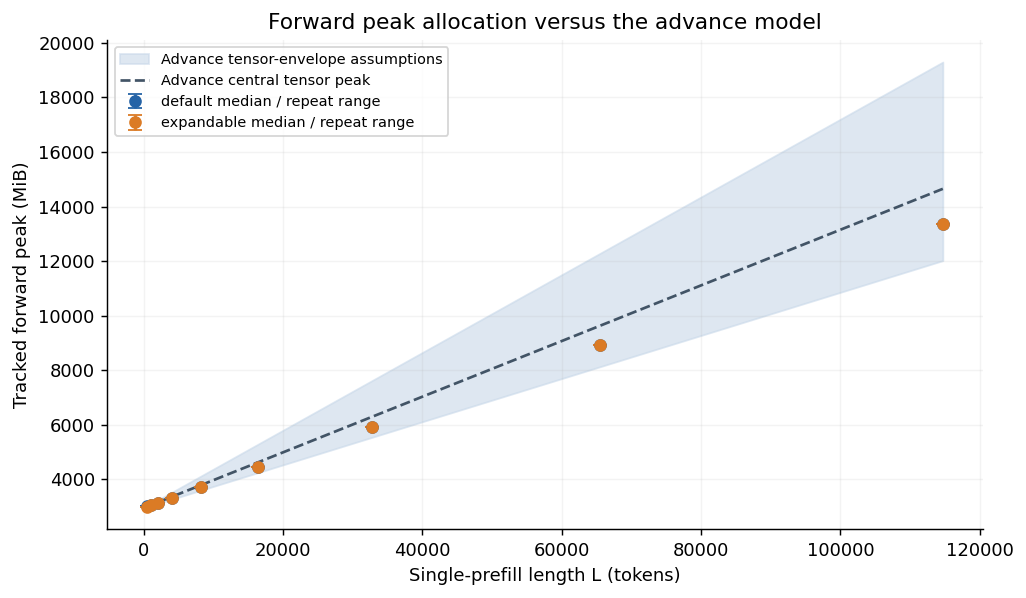

FINAL_CPU_VERIFICATION_COMPLETE e09fdf954d86a1b757b63505343d8f6cfd0e49e7


In [4]:
# Continue the recorded CPU verification; Colab's venv ensurepip failed before tests.
# Use the existing notebook Python; install CPU analysis packages only. No model/CUDA calls.
import shutil
print('CPU environment:',sys.version)
FINAL_PY=sys.executable

# Ensure the reproduction output folder is deleted if it already exists to prevent overwrite errors.
if os.path.exists('/content/p1-reproduced-results'):
    shutil.rmtree('/content/p1-reproduced-results')

final_cpu_run('dependencies-system-python',[FINAL_PY,'-m','pip','install','-e','.', '-r','requirements-analysis.txt'],FINAL_REPO)
final_cpu_run('tests',[FINAL_PY,'-m','unittest','discover','-s','tests','-v'],FINAL_REPO)
final_cpu_run('compile',[FINAL_PY,'-m','compileall','-q','src','scripts'],FINAL_REPO)
checkpoint_verification_code="import hashlib,json,subprocess,sys,tempfile,zipfile\nfrom collections import Counter\nfrom datetime import datetime,timezone\nfrom pathlib import Path\nsys.path.insert(0,str(Path.cwd()/'src'))\nfrom kv_cache_scaling.analysis import read_capsules,write_analysis\nfrom kv_cache_scaling.reporting import evidence_gaps\ncapsule=Path('artifacts/experiments/2026-10-19-t4-final/gpu-checkpoint-080.zip')\nassert hashlib.sha256(capsule.read_bytes()).hexdigest()=='cd0dedd8185a876e1a600b2c3ec8a1b95ac3701f8e22be57d2bab82f51c9c389'\nrecords,runs,sources=read_capsules([capsule]);raw=[r['record'] for r in records]\nassert len(raw)==len({r['pid'] for r in raw})==80\nassert all(r['status']=='success' for r in raw)\nassert len({(r['manifest']['gpu_uuid'],r['manifest']['environment_fingerprint'],r['manifest']['usable_bytes']) for r in runs.values()})==1\ncounts={};completion={}\nfor run_id,run in runs.items():\n events=run['events'];scope=run['manifest']['execution_scope'];results=[e for e in events if e['event']=='probe_result']\n counts[scope]=len(results);completion[scope]=events[-1]['event']=='run_finished'\n idle={e['probe_id'] for e in events if e['event']=='idle_verified'}\n assert all(e['probe_id'] in idle for e in results)\nassert counts=={'primary_sweep':48,'diagnostics':28,'calibrated_validation':4}\nassert completion=={'primary_sweep':True,'diagnostics':True,'calibrated_validation':False}\ncode_commit={r['manifest']['code_commit'] for r in runs.values()};assert code_commit=={'ce227af40476676238cbef9126807fd1d42be76b'}\ndef blob(commit,path):return subprocess.check_output(['git','show',commit+':'+path])\nreceipt_bytes=blob(next(iter(code_commit)),'prereg/final-2026-10-19/receipt.json');receipt=json.loads(receipt_bytes)\nassert all(hashlib.sha256(receipt_bytes).hexdigest()==r['manifest']['receipt_sha256'] for r in runs.values())\nprediction_bytes=blob(receipt['prediction_commit_sha'],receipt['prediction_path']);assert hashlib.sha256(prediction_bytes).hexdigest()==receipt['prediction_sha256']\nprediction=json.loads(prediction_bytes)\nfor path,digest in prediction['execution_sha256'].items():assert hashlib.sha256(blob(next(iter(code_commit)),path)).hexdigest()==digest\nexpected={name:prediction['execution_sha256']['src/kv_cache_scaling/'+name] for name in ('probe.py','telemetry.py')}\nassert all(r['code_sha256']==expected for r in raw)\nassert all(r['started_unix_ns']/1e9>datetime.fromisoformat(receipt['remote_receipt_observed_at_utc']).timestamp() for r in raw)\nwith zipfile.ZipFile(capsule) as z:\n assert 'state/global_deliberate_attempt.json' not in z.namelist()\n frozen=json.loads(z.read('audit/heldout-reference.json'))\n acknowledgements=[json.loads(line) for line in z.read('audit/external-checkpoint-receipts.jsonl').splitlines()]\n validation=next(r for r in runs.values() if r['manifest']['execution_scope']=='calibrated_validation')\n assert validation['manifest']['reference_sweep']==frozen['reference']\n assert any(a['sha256']==frozen['parent_checkpoint_sha256'] for a in acknowledgements)\n prefix='state/runs/'+frozen['reference']['run_id']+'/'\n for filename,key in [('manifest.json','manifest_sha256'),('events.jsonl','journal_sha256')]:assert hashlib.sha256(z.read(prefix+filename)).hexdigest()==frozen['reference'][key]\nheldout=[r['record'] for r in records if r['manifest']['execution_scope']=='calibrated_validation']\nassert datetime.fromisoformat(frozen['frozen_at_utc']).timestamp()<min(r['started_unix_ns'] for r in heldout)/1e9\nwith tempfile.TemporaryDirectory() as d:\n write_analysis([capsule],Path(d)/'analysis');a=json.loads((Path(d)/'analysis/analysis.json').read_text())\nassert all(a['acceptance'].values())\nmissing=evidence_gaps(a);assert len(missing)==2\nresult=dict(status='PASS_SAVED_CHECKPOINT_INTEGRITY_RESEARCH_INCOMPLETE',verified_at_utc=datetime.now(timezone.utc).isoformat(),sources=sources,successful_workers=80,unique_worker_pids=80,execution_counts=counts,completed_journals=completion,prospective_receipt_source_and_heldout_freeze_verified=True,deliberate_attempt_consumed=False,empirical_checks=a['acceptance'],research_signoff=False,missing_evidence=missing,interruption='Colab runtime removed; GPU quota prevented reconnection')\nprint(json.dumps(result,indent=2))\n"
verification=final_cpu_run('saved-checkpoint-integrity',[FINAL_PY,'-c',checkpoint_verification_code],FINAL_REPO)
final_cpu_run('reproduction',[FINAL_PY,'scripts/reproduce_results.py','--capsule','artifacts/experiments/2026-10-19-t4-final/gpu-checkpoint-080.zip','--output','/content/p1-reproduced-results'],FINAL_REPO)
print('FINAL_CPU_AUDIT_BEGIN')
print(json.dumps(final_cpu_commands,indent=2))
print('FINAL_CPU_AUDIT_END')
display(Markdown('## Person 1 saved-data delivery\n**109 CPU tests passed · 80 verified GPU workers · both allocators reached 114,688 tokens**\n\nKV slope: **28,672 bytes/token**, exactly theoretical. The five implementation phases, plots and report are integrated.\n\n**GPU acceptance is incomplete:** Colab exhausted its GPU quota. Two expandable validation repeats and the single final boundary attempt remain. No OOM threshold is claimed.\n\n[GitHub delivery](https://github.com/DevanshSharma351/KV-Cache-Scaling) · [Remaining work](https://github.com/DevanshSharma351/KV-Cache-Scaling/blob/main/docs/P1_HANDOFF.md)'))
display(Image(filename='/content/p1-reproduced-results/analysis/figures/01_peak_vs_length.png'))
print('FINAL_CPU_VERIFICATION_COMPLETE',FINAL_COMMIT)